# Mega Supermart: Workforce Performance & Absenteeism Analysis
### Exploratory Data Analysis (EDA) for Workforce Optimisation
**Prepared by:** Keren Oyem  |  **Role:** Business Intelligence Consultant  |  **Client:** Mega Supermart (Western Canada)  |  **Due:** 09 Nov 2026

---

## Project description
Mega Supermart is a large Western Canadian retail organisation reviewing how it staffs its stores and how to reduce absenteeism.
Leadership provided an **anonymised dataset of 1,200 employees across 11 stores in 4 provinces (AB, BC, MB, SK)**, covering demographics, job attributes, length of service,
scheduled hours and absent hours for 2025. This notebook performs a complete exploratory data analysis to support decisions on **staffing, scheduling and human-capital risk**.

## Business questions answered
1. **Workforce composition:** how is the workforce spread across departments, job titles, stores, business units, divisions and gender, and are there imbalances?
2. **Tenure and age structure:** what do age and service look like, and which segments are at risk of retirement or turnover?
3. **Absenteeism:** what does the absence distribution look like, who is most affected, and what is it correlated with?
4. **Risk identification:** which outliers, data issues, absence clusters, tenure extremes and understaffed areas need attention?
5. **Strategic opportunities:** where can HR, store managers and operations leaders improve things?

## Notebook map
| Phase | Section | Business question |
|---|---|---|
| 0 | Data understanding | Setup |
| 1 | Data quality review and cleaning | Task requirement |
| 2 | Descriptive analytics | Task requirement |
| 3 | Workforce composition | Q1 |
| 4 | Tenure and age structure | Q2 |
| 5 | Absenteeism analysis | Q3 |
| 6 | Risk identification | Q4 |
| 7 | Strategic opportunities and recommendations | Q5 |
| 8 | Summary dashboard and exports | Deliverables |

## How to run
1. Put the Excel file in the same folder as this notebook and name it `Mega_Supermart_Employee_Data.xlsx` (or edit `FILE` in the next cell).
2. Required packages: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `openpyxl` (install with `pip install` if missing).
3. Choose **Kernel > Restart & Run All**. Charts are saved in a `charts` folder and tables in `Keren_Oyem_Analysis_Tables.xlsx`.

## Key assumptions and definitions
- **Reference date** is 31 Dec 2025 (age and service are measured as at this date, per the data dictionary).
- **Retirement watch** is age 55+, and **high retirement risk** is age 60+. **Turnover watch** is under 1 year of service. The brief does not define these, so they are editable in the setup cell.
- **Extreme absence** is any employee above the IQR upper fence (Q3 + 1.5 x IQR) of absent hours.
- **Absence rate** is absent hours divided by scheduled hours. **FTE** equals 2,080 hours (one full-time year).
- Findings are reported at **group level only**; the data is anonymised and no attempt is made to identify individuals.
- **Placeholder hire dates:** 55 employees have a hire date of 30-31 Dec 2025 despite full-year hours and absence. They are flagged and tenure results are re-tested without them.
- Small stores (Brandon, Regina, Saskatoon) have few employees, so their averages are less stable. Group differences show association, not causation.

*Each key output is followed by a short **Interpretation** cell written for a business reader.*

In [76]:
from pathlib import Path
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

FILE = Path(r"C:\Users\HP\Desktop\Absenteeism Project\Mega_Supermart_Employee_Data.xlsx")
OUT_DIR = Path(".")                 # cleaned data and tables are saved here
CHART_DIR = Path("charts")          # charts are saved here for the report
CHART_DIR.mkdir(exist_ok=True)

# Dates and assumptions (the brief does not define these; they are stated in the report)
REF_DATE = pd.Timestamp("2025-12-31")   # reference date from the data dictionary
RETIRE_NEAR = 55     # "approaching retirement" age
RETIRE_HIGH = 60     # "high retirement risk" age
TURNOVER_YRS = 1     # early-tenure turnover risk: less than 1 year of service

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

issues = []   # issues log: (issue, field, rows_affected, action)

def log(issue, field, n, action):
    issues.append({"Issue": issue, "Field": field, "Rows affected": n, "Action": action})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(CHART_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

# PHASE 0: Data Understanding

In [4]:
if not FILE.exists():
    raise FileNotFoundError(f"Excel file not found at: {FILE.resolve()}\nEdit the FILE path in the first cell.")

raw = pd.read_excel(FILE, sheet_name="Employee Data")
dictionary = pd.read_excel(FILE, sheet_name="Data Dictionary")
df = raw.copy()

print("Shape:", df.shape)
print(dictionary.to_string(index=False))
df.info()
df.head()

Shape: (1200, 17)
               Field   Type / unit                                                         Definition
          EmployeeID          Text                                           Anonymized employee key;
             StoreID          Text                                            Store key ST01 to ST11.
                City          Text                                       Western Canadian store city.
            Province          Text                                                  AB, BC, MB or SK.
        BusinessUnit          Text                                   Prairie or Pacific retail group.
            Division          Text                                West or Central operating division.
          Department          Text                                               Employee department;
            JobTitle          Text                                            Role within department.
              Gender          Text                              

,EmployeeID,StoreID,City,Province,BusinessUnit,Division,Department,JobTitle,Gender,BirthDate,HireDate,AgeYears,LengthOfServiceYears,EmploymentType,ScheduledHours2025,AbsentHours,AbsenceRate
0,ACE00001,ST03,Red Deer,AB,Prairie,West,Operations,Store Operations Supervisor,Woman,1982-02-17,2025-12-07,43,0.07,Full-time,2080,56.0,0.0269
1,ACE00002,ST04,Vancouver,BC,Pacific,West,Sales,Sales Supervisor,Man,1980-03-16,2023-09-21,45,2.28,Full-time,2080,0.0,0.0000
2,ACE00003,ST04,Vancouver,BC,Pacific,West,Inventory,Stock Associate,Man,1991-04-14,2021-12-11,34,4.05,Full-time,2080,44.0,0.0212
3,ACE00004,ST07,Kelowna,BC,Pacific,West,Sales,Senior Sales Associate,Man,2006-11-16,2024-12-31,19,1.00,Full-time,2080,0.0,0.0000
4,ACE00005,ST04,Vancouver,BC,Pacific,West,Sales,Senior Sales Associate,Woman,1987-04-06,2025-06-08,38,0.56,Full-time,2080,56.0,0.0269


In [5]:
# Quick structural profile of every column
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
profile

,dtype,n_missing,pct_missing,n_unique
EmployeeID,str,0,0.00,1198
StoreID,str,0,0.00,11
City,str,0,0.00,11
Province,str,0,0.00,4
BusinessUnit,str,0,0.00,2
Division,str,0,0.00,2
Department,str,0,0.00,8
JobTitle,str,0,0.00,15
Gender,str,3,0.25,4
BirthDate,datetime64[us],0,0.00,1152


In [6]:
# Store hierarchy check: each store should map to ONE city / province / unit / division
hierarchy = df.groupby(["StoreID", "City", "Province", "BusinessUnit", "Division"]).size().rename("Headcount")
print(hierarchy)
assert df.groupby("StoreID")[["City", "Province", "BusinessUnit", "Division"]].nunique().max().max() == 1, \
    "A store maps to more than one city/province/unit/division"

StoreID  City       Province  BusinessUnit  Division
ST01     Calgary    AB        Prairie       West        225
ST02     Edmonton   AB        Prairie       West        203
ST03     Red Deer   AB        Prairie       West         91
ST04     Vancouver  BC        Pacific       West        187
ST05     Surrey     BC        Pacific       West        152
ST06     Victoria   BC        Pacific       West         76
ST07     Kelowna    BC        Pacific       West         93
ST08     Winnipeg   MB        Prairie       Central      81
ST09     Brandon    MB        Prairie       Central      40
ST10     Regina     SK        Prairie       Central      30
ST11     Saskatoon  SK        Prairie       Central      22
Name: Headcount, dtype: int64


**Interpretation: structure of the data.**
The file holds **1,200 employees across 11 stores in 4 provinces** (Alberta, British Columbia, Manitoba, Saskatchewan). Each store maps cleanly to one city, province, business unit and division (the check above would stop with an error otherwise),
so store-level comparisons are reliable. Store sizes are very uneven: Calgary has 225 employees, while Saskatoon has only 22. We keep this in mind when comparing averages.

# PHASE 1: Data Quality Review and Cleaning

### 1.1 Missing values

In [7]:
missing = df.isna().sum()
print(missing[missing > 0])
print(df[df.isna().any(axis=1)][["EmployeeID", "Gender", "AbsentHours", "AbsenceRate"]])

Gender         3
AbsentHours    2
AbsenceRate    2
dtype: int64
    EmployeeID Gender  AbsentHours  AbsenceRate
84    ACE00085    NaN         36.0       0.0173
200   ACE00201    Man          NaN          NaN
379   ACE00380    NaN         32.0       0.0154
703   ACE00704  Woman          NaN          NaN
908   ACE00909    NaN          0.0       0.0000


**Interpretation: missing values.**
Missing data is minimal: **3 employees have no Gender** and **2 have no absence data** (AbsentHours and AbsenceRate are missing together). That is under 0.5% of records, so it cannot distort the results. We do not guess (impute) missing absence,
because that would invent behaviour; those two people stay in the headcount analysis only.

### 1.2 Duplicates

In [8]:
full_dups = df.duplicated().sum()
id_dups = df["EmployeeID"].duplicated().sum()
print("Fully duplicated rows:", full_dups)
print("Duplicated EmployeeIDs:", id_dups)
dup_rows = df[df["EmployeeID"].duplicated(keep=False)].sort_values("EmployeeID")
dup_rows

Fully duplicated rows: 0
Duplicated EmployeeIDs: 2


,EmployeeID,StoreID,City,Province,BusinessUnit,Division,Department,JobTitle,Gender,BirthDate,HireDate,AgeYears,LengthOfServiceYears,EmploymentType,ScheduledHours2025,AbsentHours,AbsenceRate
1141,ACE01142,ST05,Surrey,BC,Pacific,West,Management,Store Manager,Man,2006-01-23,2024-12-31,19,1.00,Full-time,2080,40.0,0.0192
1142,ACE01142,ST07,Kelowna,BC,Pacific,West,Human Resources,HR Coordinator,Woman,1980-11-02,2025-12-30,45,0.00,Full-time,2080,24.0,0.0115
1152,ACE01153,ST02,Edmonton,AB,Prairie,West,Inventory,Inventory Clerk,Man,1991-05-07,2024-03-06,34,1.82,Full-time,2080,20.0,0.0096
1153,ACE01153,ST08,Winnipeg,MB,Prairie,Central,Human Resources,HR Coordinator,Woman,1982-11-15,2023-11-09,43,2.14,Full-time,2080,52.0,0.0250


**Interpretation: duplicates.**
There are **no fully duplicated rows**, but **2 EmployeeIDs appear twice**. In each case the two records are different people (different store, job title and birth date), so they are not true duplicates. Deleting one would wrongly remove a real employee,
so we keep all four rows and add a unique `RecordID`. This is an **ID-integrity problem** in the source system that the client should fix.

### 1.3 Inconsistent labels and data types

In [9]:
for col in ["StoreID", "City", "Province", "BusinessUnit", "Division",
            "Department", "JobTitle", "Gender", "EmploymentType"]:
    print(f"\n{col}\n{df[col].value_counts(dropna=False).to_string()}")


StoreID
StoreID
ST01    225
ST02    203
ST04    187
ST05    152
ST07     93
ST03     91
ST08     81
ST06     76
ST09     40
ST10     30
ST11     22

City
City
Calgary      225
Edmonton     203
Vancouver    187
Surrey       152
Kelowna       93
Red Deer      91
Winnipeg      81
Victoria      76
Brandon       40
Regina        30
Saskatoon     22

Province
Province
AB    519
BC    508
MB    121
SK     52

BusinessUnit
BusinessUnit
Prairie    692
Pacific    508

Division
Division
West       1027
Central     173

Department
Department
Sales               444
Inventory           228
Customer Service    190
Operations          139
Management          129
Human Resources      68
sales                 1
Customer service      1

JobTitle
JobTitle
Senior Sales Associate         155
Sales Associate                152
Sales Supervisor               138
Inventory Clerk                 86
Store Operations Supervisor     74
Stock Associate                 71
Inventory Supervisor            71
Assista

In [10]:
# Whitespace / case problems in text columns
text_cols = df.select_dtypes(include=["object", "string"]).columns
for c in text_cols:
    s = df[c].dropna().astype(str)
    n_ws = (s != s.str.strip()).sum()
    if n_ws:
        print(f"{c}: {n_ws} values with leading/trailing whitespace")

In [11]:
# Department vs JobTitle consistency: every JobTitle should belong to ONE department
title_dept = df.groupby("JobTitle")["Department"].agg(lambda s: s.value_counts().to_dict())
print(title_dept.to_string())

# Rows whose Department label is a case variant OR does not match the title's dominant department
dominant = df.groupby("JobTitle")["Department"].agg(lambda s: s.value_counts().idxmax())
df["_dominant_dept"] = df["JobTitle"].map(dominant)
mismatch = df[df["Department"] != df["_dominant_dept"]]
print("\nDepartment / JobTitle mismatches:")
print(mismatch[["EmployeeID", "StoreID", "Department", "JobTitle", "_dominant_dept"]])

JobTitle
Assistant Store Manager                           {'Management': 71}
Customer Service Associate                  {'Customer Service': 69}
Customer Service Supervisor     {'Customer Service': 54, 'sales': 1}
HR Business Partner                          {'Human Resources': 40}
HR Coordinator                               {'Human Resources': 28}
Inventory Clerk                                    {'Inventory': 86}
Inventory Supervisor                               {'Inventory': 71}
Operations Coordinator                            {'Operations': 65}
Returns Specialist                          {'Customer Service': 67}
Sales Associate                                       {'Sales': 152}
Sales Supervisor               {'Sales': 137, 'Customer service': 1}
Senior Sales Associate                                {'Sales': 155}
Stock Associate                                    {'Inventory': 71}
Store Manager                                     {'Management': 58}
Store Operations Supervis

**Interpretation: label consistency.**
Two records have a Department that contradicts the job title: a *Customer Service Supervisor* labelled "sales" and a *Sales Supervisor* labelled "Customer service" (the capitalisation is also inconsistent). The job title is more specific,
so we correct the department from the title and flag the pair for client confirmation.

### 1.4 Logical consistency checks (dates, age, tenure, absence rate)

In [12]:
age_calc = ((REF_DATE - df["BirthDate"]).dt.days / 365.25).astype(int)
los_calc = (REF_DATE - df["HireDate"]).dt.days / 365.25
hire_age = (df["HireDate"] - df["BirthDate"]).dt.days / 365.25
rate_calc = df["AbsentHours"] / df["ScheduledHours2025"]

checks = {
    "Age differs from BirthDate-derived age": int((age_calc != df["AgeYears"]).sum()),
    "Tenure differs from HireDate-derived tenure (>0.05 yr)": int(((los_calc - df["LengthOfServiceYears"]).abs() > 0.05).sum()),
    "Hired before age 16": int((hire_age < 16).sum()),
    "Hire date after reference date": int((df["HireDate"] > REF_DATE).sum()),
    "Negative tenure": int((df["LengthOfServiceYears"] < 0).sum()),
    "AbsenceRate differs from AbsentHours/Scheduled": int(((rate_calc - df["AbsenceRate"]).abs() > 0.0005).sum()),
    "Absent hours > scheduled hours": int((df["AbsentHours"] > df["ScheduledHours2025"]).sum()),
    "Negative absent hours": int((df["AbsentHours"] < 0).sum()),
    "Zero-tenure employees (hired in last days of 2025)": int((df["LengthOfServiceYears"] == 0).sum()),
}
pd.Series(checks, name="count")

Age differs from BirthDate-derived age                     0
Tenure differs from HireDate-derived tenure (>0.05 yr)     0
Hired before age 16                                        0
Hire date after reference date                             0
Negative tenure                                            0
AbsenceRate differs from AbsentHours/Scheduled             0
Absent hours > scheduled hours                             0
Negative absent hours                                      0
Zero-tenure employees (hired in last days of 2025)        55
Name: count, dtype: int64

In [13]:
# Zero-tenure employees: are they genuine new hires, or placeholder hire dates?
zero = df[df["LengthOfServiceYears"] == 0]
print("Hire dates of zero-tenure employees:")
print(zero["HireDate"].dt.date.value_counts().to_string())
print("\nScheduled hours of these employees (a full year would be 2,080):")
print(zero["ScheduledHours2025"].value_counts().to_string())
print(f"\nMean absent hours recorded for them: {zero['AbsentHours'].mean():.0f} (max {zero['AbsentHours'].max():.0f})")

# Hires per month in the second half of 2025: is December unusual?
recent = df[df["HireDate"] >= "2025-07-01"]
recent.groupby(recent["HireDate"].dt.to_period("M")).size().rename("Hires").to_frame()

Hire dates of zero-tenure employees:
HireDate
2025-12-31    54
2025-12-30     1

Scheduled hours of these employees (a full year would be 2,080):
ScheduledHours2025
2080    41
1248     6
1040     5
1560     3

Mean absent hours recorded for them: 78 (max 400)


,Hires
HireDate,
2025-07,20
2025-08,12
2025-09,19
2025-10,17
2025-11,19
2025-12,65


**Interpretation: suspicious hire dates.**
All 8 logic checks above come back clean (0 problems) except one: **55 employees have zero service because their hire date is 30 or 31 December 2025**. Yet most of them show a full year of scheduled hours (41 of 55 have 2,080) and an average of **78 absent hours**,
which is impossible for someone hired on the last day of the year. December also shows 65 "hires" against about 17 in a typical month. These look like **placeholder hire dates** (a default date when the true date is unknown), not real new starters.
We keep the records, flag them (`HireDatePlaceholder`), and re-test all tenure findings without them.

In [14]:
# Scheduled hours should line up with employment type
print(pd.crosstab(df["EmploymentType"], df["ScheduledHours2025"]))

ScheduledHours2025  1040  1248  1560  2080
EmploymentType                            
Full-time              0     0     0   863
Part-time            115   118   104     0


In [15]:
# Implausible seniority: managers aged under 25 (judgement call; flag, do not delete)
mgr = df["JobTitle"].isin(["Store Manager", "Assistant Store Manager"])
young_mgr = df[mgr & (df["AgeYears"] < 25)]
print("Managers / assistant managers under 25:", len(young_mgr))
young_mgr[["EmployeeID", "JobTitle", "AgeYears", "LengthOfServiceYears", "StoreID"]].head(15)

Managers / assistant managers under 25: 13


,EmployeeID,JobTitle,AgeYears,LengthOfServiceYears,StoreID
48,ACE00049,Assistant Store Manager,18,0.00,ST07
55,ACE00056,Assistant Store Manager,21,3.00,ST02
96,ACE00097,Store Manager,18,0.00,ST02
158,ACE00159,Store Manager,18,0.00,ST02
265,ACE00266,Store Manager,22,1.83,ST10
523,ACE00524,Store Manager,23,1.08,ST07
577,ACE00578,Store Manager,20,2.00,ST07
596,ACE00597,Assistant Store Manager,19,1.00,ST02
761,ACE00762,Store Manager,21,3.00,ST02
826,ACE00827,Store Manager,18,0.00,ST01


**Interpretation: implausible seniority.**
13 store managers or assistant managers are under 25, which is unusual for these roles. They could be genuine fast promotions or job-title coding errors. We keep them (flagged) and ask the client to validate, since this affects any
analysis of management age. Separately, there are 58 "Store Manager" titles for only 11 stores, so the title probably means a department-level manager; this definition should be clarified.

### 1.5 Outliers in absent hours (IQR and z-score)

In [16]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

lo, hi = iqr_bounds(df["AbsentHours"].dropna())
z = (df["AbsentHours"] - df["AbsentHours"].mean()) / df["AbsentHours"].std()
df["abs_outlier_iqr"] = df["AbsentHours"] > hi
df["abs_outlier_z3"] = z.abs() > 3

print(f"IQR upper fence: {hi:.1f} hours  -> {df['abs_outlier_iqr'].sum()} employees")
print(f"|z| > 3: {df['abs_outlier_z3'].sum()} employees")
print(df["AbsentHours"].describe(percentiles=[.5, .9, .95, .99]))

df.loc[df["abs_outlier_z3"], ["EmployeeID", "JobTitle", "StoreID", "ScheduledHours2025",
                              "AbsentHours", "AbsenceRate"]].sort_values("AbsentHours", ascending=False)

IQR upper fence: 142.0 hours  -> 50 employees
|z| > 3: 15 employees
count    1198.000000
mean       46.731219
std        59.411254
min         0.000000
50%        32.000000
90%       104.000000
95%       132.600000
99%       240.240000
max       720.000000
Name: AbsentHours, dtype: float64


,EmployeeID,JobTitle,StoreID,ScheduledHours2025,AbsentHours,AbsenceRate
1000,ACE01001,Customer Service Associate,ST08,2080,720.0,0.3462
326,ACE00327,HR Business Partner,ST06,1248,600.0,0.4808
393,ACE00394,Sales Supervisor,ST02,1040,600.0,0.5769
42,ACE00043,Sales Associate,ST02,2080,496.0,0.2385
1045,ACE01046,Senior Sales Associate,ST05,2080,496.0,0.2385
69,ACE00070,Inventory Supervisor,ST08,2080,420.0,0.2019
636,ACE00637,Sales Associate,ST01,2080,420.0,0.2019
825,ACE00826,Senior Sales Associate,ST10,1040,400.0,0.3846
439,ACE00440,Sales Associate,ST05,2080,344.0,0.1654
1134,ACE01135,Customer Service Supervisor,ST10,2080,308.0,0.1481


**Interpretation: outliers.**
**Absent hours:** using the IQR rule, any employee above **142 hours** is extreme, which flags **50 people (about 4%)**; a stricter z-score test (beyond 3 standard deviations) flags 15. The largest value is **720 hours (a 58% absence rate)**.
These are real-looking values (long-term illness or leave is plausible), so we **keep and flag** them rather than delete, and later show results with and without them. **Age and scheduled hours have no outliers.** The 52 tenure "outliers" are simply long-serving
employees (up to 27 years), which is legitimate.

In [17]:
# Other numeric fields
for col in ["AgeYears", "LengthOfServiceYears", "ScheduledHours2025"]:
    lo_c, hi_c = iqr_bounds(df[col])
    n = ((df[col] < lo_c) | (df[col] > hi_c)).sum()
    print(f"{col}: IQR fences [{lo_c:.1f}, {hi_c:.1f}] -> {n} flagged")

AgeYears: IQR fences [4.5, 72.5] -> 0 flagged
LengthOfServiceYears: IQR fences [-6.9, 14.6] -> 52 flagged
ScheduledHours2025: IQR fences [780.0, 2860.0] -> 0 flagged


## Clean-up (every fix is logged)

In [18]:
clean = df.drop(columns=["_dominant_dept"]).copy()

# 1) Standardise Department labels (case / spacing variants)
dept_map = {"sales": "Sales", "customer service": "Customer Service"}
before = clean["Department"].copy()
clean["Department"] = (clean["Department"].str.strip()
                       .apply(lambda x: dept_map.get(x.lower(), x)))
n_fix = int((before != clean["Department"]).sum())
log("Inconsistent Department capitalisation ('sales', 'Customer service')", "Department", n_fix,
    "Standardised to 'Sales' / 'Customer Service'")

# 2) Department vs JobTitle conflict: after case fix, the title decides the department
dominant = clean.groupby("JobTitle")["Department"].agg(lambda s: s.value_counts().idxmax())
conflict = clean["Department"] != clean["JobTitle"].map(dominant)
n_conf = int(conflict.sum())
if n_conf:
    log("Department contradicts JobTitle (e.g. 'Sales Supervisor' tagged Customer Service)", "Department",
        n_conf, "Re-assigned Department from JobTitle (title is more specific). Flagged for client confirmation")
    clean.loc[conflict, "Department"] = clean.loc[conflict, "JobTitle"].map(dominant)

# 3) Duplicate EmployeeIDs: same ID, different people (different store, title, birth date)
dup_mask = clean["EmployeeID"].duplicated(keep=False)
n_dup = int(dup_mask.sum())
log("Duplicate EmployeeID shared by two different people (different store, title, DOB)", "EmployeeID",
    n_dup, "Kept both records (they are not true duplicates); created unique RecordID for safe joins")
clean["RecordID"] = np.arange(1, len(clean) + 1)

# 4) Missing Gender -> explicit category so rows are not dropped
n_g = int(clean["Gender"].isna().sum())
log("Missing Gender", "Gender", n_g, "Filled with 'Not recorded' (kept distinct from 'Prefer not to say')")
clean["Gender"] = clean["Gender"].fillna("Not recorded")

# 5) Missing AbsentHours / AbsenceRate -> excluded from absence metrics only (no imputation)
n_a = int(clean["AbsentHours"].isna().sum())
log("Missing AbsentHours and AbsenceRate", "AbsentHours / AbsenceRate", n_a,
    "Not imputed (would bias averages). Kept for headcount, excluded from absence analysis")
clean["AbsenceDataMissing"] = clean["AbsentHours"].isna()

# 6) Outliers: flag, do not delete (extreme absence may be real long-term leave)
clean["AbsenceOutlier"] = clean["AbsentHours"] > hi
log("Extreme absent hours (above IQR fence)", "AbsentHours", int(clean["AbsenceOutlier"].sum()),
    "Retained and flagged. Report medians alongside means; check effect with/without")

# 7) Implausible seniority flag
clean["ImplausibleSeniority"] = mgr & (clean["AgeYears"] < 25)
log("Managers / assistant managers aged under 25 (possible job-title coding issue)", "JobTitle / AgeYears",
    int(clean["ImplausibleSeniority"].sum()), "Retained and flagged for client validation")

# 7b) Placeholder hire dates (hired 30-31 Dec 2025 but with a full year of scheduled hours and absence)
clean["HireDatePlaceholder"] = clean["LengthOfServiceYears"] == 0
log("Hire date on 30-31 Dec 2025 (zero tenure) although full-year scheduled hours and absence are recorded: likely placeholder dates",
    "HireDate / LengthOfServiceYears", int(clean["HireDatePlaceholder"].sum()),
    "Retained and flagged. Tenure findings are re-tested without these records; client to confirm true hire dates")

# 8) Type enforcement
for c in ["StoreID", "City", "Province", "BusinessUnit", "Division", "Department",
          "JobTitle", "Gender", "EmploymentType"]:
    clean[c] = clean[c].astype("category")
clean["BirthDate"] = pd.to_datetime(clean["BirthDate"])
clean["HireDate"] = pd.to_datetime(clean["HireDate"])

# 9) Derived fields used later
clean["AgeBand"] = pd.cut(clean["AgeYears"], [17, 24, 34, 44, 54, 59, 100],
                          labels=["18-24", "25-34", "35-44", "45-54", "55-59", "60+"])
clean["TenureBand"] = pd.cut(clean["LengthOfServiceYears"], [0, 1, 3, 5, 10, 100], right=False,
                             labels=["<1 yr", "1-<3 yrs", "3-<5 yrs", "5-<10 yrs", "10+ yrs"])

In [19]:
issues_log = pd.DataFrame(issues)
issues_log

,Issue,Field,Rows affected,Action
0,Inconsistent Department capitalisation ('sales...,Department,2,Standardised to 'Sales' / 'Customer Service'
1,Department contradicts JobTitle (e.g. 'Sales S...,Department,2,Re-assigned Department from JobTitle (title is...
2,Duplicate EmployeeID shared by two different p...,EmployeeID,4,Kept both records (they are not true duplicate...
3,Missing Gender,Gender,3,Filled with 'Not recorded' (kept distinct from...
4,Missing AbsentHours and AbsenceRate,AbsentHours / AbsenceRate,2,Not imputed (would bias averages). Kept for he...
5,Extreme absent hours (above IQR fence),AbsentHours,50,Retained and flagged. Report medians alongside...
6,Managers / assistant managers aged under 25 (p...,JobTitle / AgeYears,13,Retained and flagged for client validation
7,Hire date on 30-31 Dec 2025 (zero tenure) alth...,HireDate / LengthOfServiceYears,55,Retained and flagged. Tenure findings are re-t...


**Interpretation: issues log.**
This table is the audit trail of every data problem found and what we did about it. Nothing was silently deleted: the dataset still has all **1,200 rows**, with problems either corrected (labels), flagged (outliers, placeholder hire dates, young managers)
or left unimputed (missing absence). The two items that need client confirmation are the **duplicate IDs** and the **placeholder hire dates**.

## Validation: before vs after

In [20]:
print("Rows before:", len(raw), "| after:", len(clean))
print("Department values after:", sorted(clean["Department"].unique()))
print("Missing after:\n", clean[["Gender", "AbsentHours"]].isna().sum())
assert clean["Department"].nunique() == 6
assert len(clean) == len(raw)

Rows before: 1200 | after: 1200
Department values after: ['Customer Service', 'Human Resources', 'Inventory', 'Management', 'Operations', 'Sales']
Missing after:
 Gender         0
AbsentHours    2
dtype: int64


In [21]:
# Export cleaned data and issues log for the next phases
clean.to_csv(OUT_DIR / "Keren_Oyem_Clean_Employees.csv", index=False)
issues_log.to_csv(OUT_DIR / "Keren_Oyem_Issues_Log.csv", index=False)
print("Saved Keren_Oyem_Clean_Employees.csv and Keren_Oyem_Issues_Log.csv in:", OUT_DIR.resolve())

Saved Keren_Oyem_Clean_Employees.csv and Keren_Oyem_Issues_Log.csv in: C:\Users\HP\Desktop\Absenteeism Project


# PHASE 2: Descriptive Analytics
We now work with the cleaned data (`df`).

In [22]:
df = clean.copy()      # continue from the cleaned data created in Phase 1 (no need to reload a file)

cat_cols = ["StoreID", "City", "Province", "BusinessUnit", "Division",
            "Department", "JobTitle", "Gender", "EmploymentType"]
for c in cat_cols:
    df[c] = df[c].astype("category")

# Order the bands so charts and tables read low -> high
df["AgeBand"] = pd.Categorical(df["AgeBand"], ["18-24", "25-34", "35-44", "45-54", "55-59", "60+"], ordered=True)
df["TenureBand"] = pd.Categorical(df["TenureBand"], ["<1 yr", "1-<3 yrs", "3-<5 yrs", "5-<10 yrs", "10+ yrs"], ordered=True)

# Store label used on charts: City (StoreID)
df["Store"] = df["City"].astype(str) + " (" + df["StoreID"].astype(str) + ")"
print(df.shape)
df.head()

(1200, 27)


,EmployeeID,StoreID,City,Province,BusinessUnit,Division,Department,JobTitle,Gender,BirthDate,HireDate,AgeYears,LengthOfServiceYears,EmploymentType,ScheduledHours2025,AbsentHours,AbsenceRate,abs_outlier_iqr,abs_outlier_z3,RecordID,AbsenceDataMissing,AbsenceOutlier,ImplausibleSeniority,HireDatePlaceholder,AgeBand,TenureBand,Store
0,ACE00001,ST03,Red Deer,AB,Prairie,West,Operations,Store Operations Supervisor,Woman,1982-02-17,2025-12-07,43,0.07,Full-time,2080,56.0,0.0269,False,False,1,False,False,False,False,35-44,<1 yr,Red Deer (ST03)
1,ACE00002,ST04,Vancouver,BC,Pacific,West,Sales,Sales Supervisor,Man,1980-03-16,2023-09-21,45,2.28,Full-time,2080,0.0,0.0000,False,False,2,False,False,False,False,45-54,1-<3 yrs,Vancouver (ST04)
2,ACE00003,ST04,Vancouver,BC,Pacific,West,Inventory,Stock Associate,Man,1991-04-14,2021-12-11,34,4.05,Full-time,2080,44.0,0.0212,False,False,3,False,False,False,False,25-34,3-<5 yrs,Vancouver (ST04)
3,ACE00004,ST07,Kelowna,BC,Pacific,West,Sales,Senior Sales Associate,Man,2006-11-16,2024-12-31,19,1.00,Full-time,2080,0.0,0.0000,False,False,4,False,False,False,False,18-24,1-<3 yrs,Kelowna (ST07)
4,ACE00005,ST04,Vancouver,BC,Pacific,West,Sales,Senior Sales Associate,Woman,1987-04-06,2025-06-08,38,0.56,Full-time,2080,56.0,0.0269,False,False,5,False,False,False,False,35-44,<1 yr,Vancouver (ST04)


### 2.1 Summary statistics for numerical fields

In [23]:
num_cols = ["AgeYears", "LengthOfServiceYears", "ScheduledHours2025", "AbsentHours", "AbsenceRate"]
summary = df[num_cols].describe(percentiles=[.25, .5, .75, .9]).T
summary["skew"] = df[num_cols].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,90%,max,skew
AgeYears,1200.0,38.59,11.29,18.0,30.00,38.00,47.00,53.00,66.00,0.09
LengthOfServiceYears,1200.0,4.54,4.50,0.0,1.17,3.06,6.52,10.81,27.00,1.59
ScheduledHours2025,1200.0,1853.45,379.41,1040.0,1560.00,2080.00,2080.00,2080.00,2080.00,-1.23
AbsentHours,1198.0,46.73,59.41,0.0,12.00,32.00,64.00,104.00,720.00,4.53
AbsenceRate,1198.0,0.03,0.04,0.0,0.01,0.02,0.04,0.06,0.58,5.99


**Interpretation: numerical summary.**
**Age** is balanced around a median of 38 (range 18 to 66, skew near zero). **Length of service** is right-skewed (median 3.1 years, mean 4.5, maximum 27): many recent joiners and a small long-serving core.
**Scheduled hours** have a median of 2,080 (full-time) but a mean of 1,853 because part-time staff are scheduled 1,040 to 1,560 hours. **Absent hours** are strongly skewed (median 32, mean 47, maximum 720), which is why medians matter for absence.

### 2.2 Frequency breakdowns of categorical fields

In [24]:
def freq(col):
    t = df[col].value_counts().rename("Headcount").to_frame()
    t["Share %"] = (t["Headcount"] / len(df) * 100).round(1)
    return t

for col in ["Department", "JobTitle", "Store", "Province", "BusinessUnit",
            "Division", "Gender", "EmploymentType"]:
    print(f"\n=== {col} ===")
    print(freq(col).to_string())


=== Department ===
                  Headcount  Share %
Department                          
Sales                   445     37.1
Inventory               228     19.0
Customer Service        191     15.9
Operations              139     11.6
Management              129     10.8
Human Resources          68      5.7

=== JobTitle ===
                             Headcount  Share %
JobTitle                                       
Senior Sales Associate             155     12.9
Sales Associate                    152     12.7
Sales Supervisor                   138     11.5
Inventory Clerk                     86      7.2
Store Operations Supervisor         74      6.2
Assistant Store Manager             71      5.9
Inventory Supervisor                71      5.9
Stock Associate                     71      5.9
Customer Service Associate          69      5.8
Returns Specialist                  67      5.6
Operations Coordinator              65      5.4
Store Manager                       58    

**Interpretation: categorical breakdowns.**
Sales is the largest department (37%), followed by Inventory (19%) and Customer Service (16%). Four stores (Calgary, Edmonton, Vancouver, Surrey) hold about 64% of staff.
Alberta (43%) and British Columbia (42%) dominate; Manitoba (10%) and Saskatchewan (4%) are small. Gender is evenly split between men (49%) and women (47%), and 72% of employees are full-time.

### 2.3 Workforce demographic profile

In [25]:
profile = pd.DataFrame({
    "Employees": [len(df)],
    "Mean age": [df.AgeYears.mean()],
    "Median age": [df.AgeYears.median()],
    "Mean tenure (yrs)": [df.LengthOfServiceYears.mean()],
    "Median tenure (yrs)": [df.LengthOfServiceYears.median()],
    "% Woman": [(df.Gender == "Woman").mean() * 100],
    "% Man": [(df.Gender == "Man").mean() * 100],
    "% Full-time": [(df.EmploymentType == "Full-time").mean() * 100],
    "% Age 55+": [(df.AgeYears >= RETIRE_NEAR).mean() * 100],
    "% Tenure <1 yr": [(df.LengthOfServiceYears < TURNOVER_YRS).mean() * 100],
}).T.rename(columns={0: "Value"}).round(1)
profile

,Value
Employees,1200.0
Mean age,38.6
Median age,38.0
Mean tenure (yrs),4.5
Median tenure (yrs),3.1
% Woman,46.8
% Man,49.1
% Full-time,71.9
% Age 55+,8.2
% Tenure <1 yr,20.6


**Interpretation: workforce profile.**
The typical employee is about **38 years old, has about 3 years of service, and works full-time**. About 8% are 55+ and 21% have under one year of service. Women and men are almost equally represented (47% and 49%).
The age-by-gender table shows a close-to-even mix in most age bands (men are somewhat more common among 18 to 24 year-olds), and the tenure table shows full-time staff make up the majority of every tenure band.

In [26]:
# Age band x Gender and Tenure band x Employment type
print(pd.crosstab(df.AgeBand, df.Gender, margins=True))
print()
print(pd.crosstab(df.TenureBand, df.EmploymentType, margins=True))

Gender   Man  Non-binary  Not recorded  Prefer not to say  Woman   All
AgeBand                                                               
18-24     77           4             2                  2     58   143
25-34    136           9             0                 10    146   301
35-44    176           7             0                  4    186   373
45-54    148           2             1                  6    127   284
55-59     32           0             0                  1     26    59
60+       20           0             0                  1     19    40
All      589          22             3                 24    562  1200

EmploymentType  Full-time  Part-time   All
TenureBand                                
<1 yr                 191         56   247
1-<3 yrs              245         88   333
3-<5 yrs              149         63   212
5-<10 yrs             191         79   270
10+ yrs                87         51   138
All                   863        337  1200


# PHASE 3: Workforce Composition (Business Question 1)

### 3.1 Headcount by department (Chart 1)

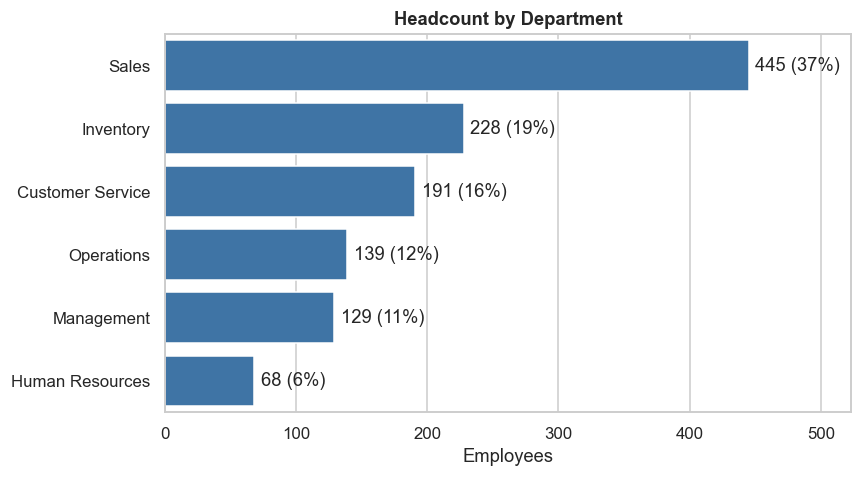

In [28]:
order = df.Department.value_counts().index
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df, y="Department", order=order, color="#2E75B6", ax=ax)
for p in ax.patches:
    ax.text(p.get_width() + 5, p.get_y() + p.get_height() / 2,
            f"{int(p.get_width())} ({p.get_width()/len(df)*100:.0f}%)", va="center")
ax.set_title("Headcount by Department")
ax.set_xlabel("Employees"); ax.set_ylabel("")
ax.set_xlim(0, ax.get_xlim()[1] * 1.12)
save(fig, "01_headcount_by_department"); plt.show()

**Interpretation: departments.**
Sales is by far the largest department with **445 employees (37%)**, larger than Inventory (228, 19%) and Customer Service (191, 16%) combined. HR is the smallest at 68 (6%).
The workforce is therefore **customer-facing heavy**, which matters because these departments also show the highest absence (Phase 5).

### 3.2 Headcount by job title (Chart 2)

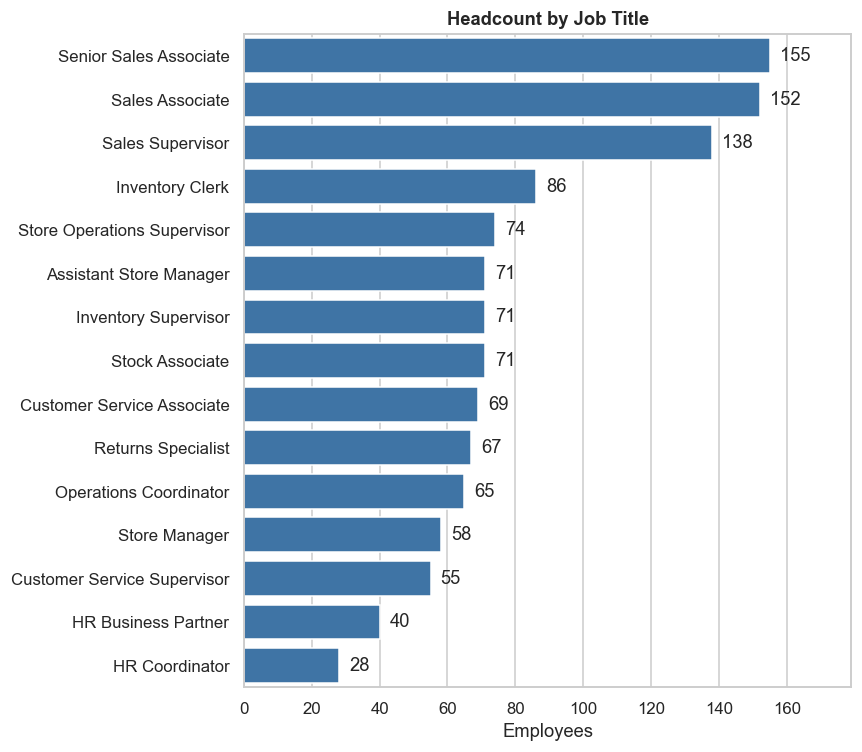

In [29]:
order = df.JobTitle.value_counts().index
fig, ax = plt.subplots(figsize=(8, 7))
sns.countplot(data=df, y="JobTitle", order=order, color="#2E75B6", ax=ax)
for p in ax.patches:
    ax.text(p.get_width() + 3, p.get_y() + p.get_height() / 2, f"{int(p.get_width())}", va="center")
ax.set_title("Headcount by Job Title")
ax.set_xlabel("Employees"); ax.set_ylabel("")
ax.set_xlim(0, ax.get_xlim()[1] * 1.1)
save(fig, "02_headcount_by_job_title"); plt.show()

**Interpretation: job titles.**
Three Sales roles top the list (Senior Sales Associate 155, Sales Associate 152, Sales Supervisor 138). One notable point is the **supervision structure**: there are 338 supervisor titles and 129 store or assistant manager titles,
so **about 39% of employees hold a supervisory or management title**. In Sales there is one supervisor for roughly every 2 associates. This is either a very supervision-heavy structure or a sign that job titles are used generously; it is worth
reviewing whether supervisory capacity is well used.

### 3.3 Headcount by store / city (Chart 3)

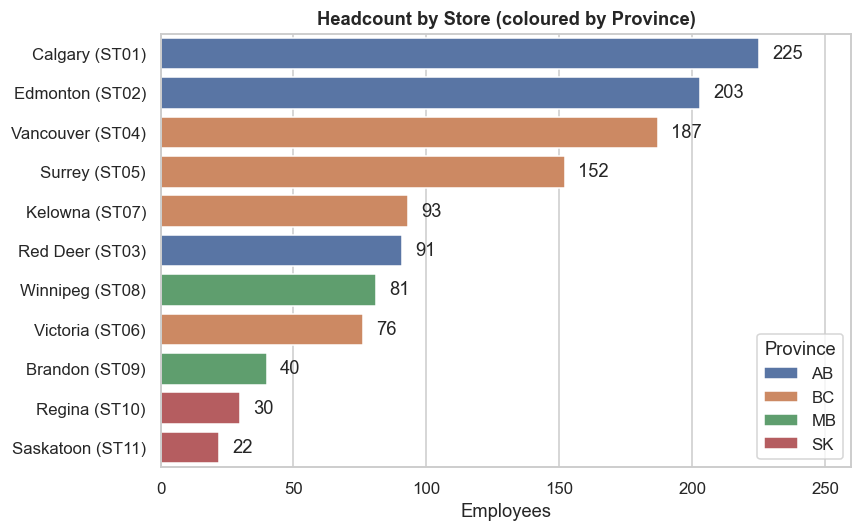

,Store,Province,BusinessUnit,Division,Headcount
1,Calgary (ST01),AB,Prairie,West,225
2,Edmonton (ST02),AB,Prairie,West,203
8,Vancouver (ST04),BC,Pacific,West,187
7,Surrey (ST05),BC,Pacific,West,152
3,Kelowna (ST07),BC,Pacific,West,93
4,Red Deer (ST03),AB,Prairie,West,91
10,Winnipeg (ST08),MB,Prairie,Central,81
9,Victoria (ST06),BC,Pacific,West,76
0,Brandon (ST09),MB,Prairie,Central,40
5,Regina (ST10),SK,Prairie,Central,30


In [30]:
store_hc = df.groupby(["Store", "Province", "BusinessUnit", "Division"], observed=True).size().rename("Headcount").reset_index()
store_hc = store_hc.sort_values("Headcount", ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=store_hc, y="Store", x="Headcount", hue="Province", dodge=False, ax=ax)
for p in ax.patches:
    if p.get_width() > 0:
        ax.text(p.get_width() + 5, p.get_y() + p.get_height() / 2, f"{int(p.get_width())}", va="center")
ax.set_title("Headcount by Store (coloured by Province)")
ax.set_xlabel("Employees"); ax.set_ylabel("")
ax.set_xlim(0, ax.get_xlim()[1] * 1.1)
save(fig, "03_headcount_by_store"); plt.show()
store_hc

**Interpretation: stores.**
Calgary (225) and Edmonton (203) are the largest stores, and the four biggest stores hold 64% of employees. The three smallest stores, **Brandon (40), Regina (30) and Saskatoon (22)**, hold under 8% combined. This size gap means small stores
have far less depth to cover absences or specialist roles, a theme that returns in the risk analysis.

### 3.4 Business Unit, Division and Gender (Chart 4)

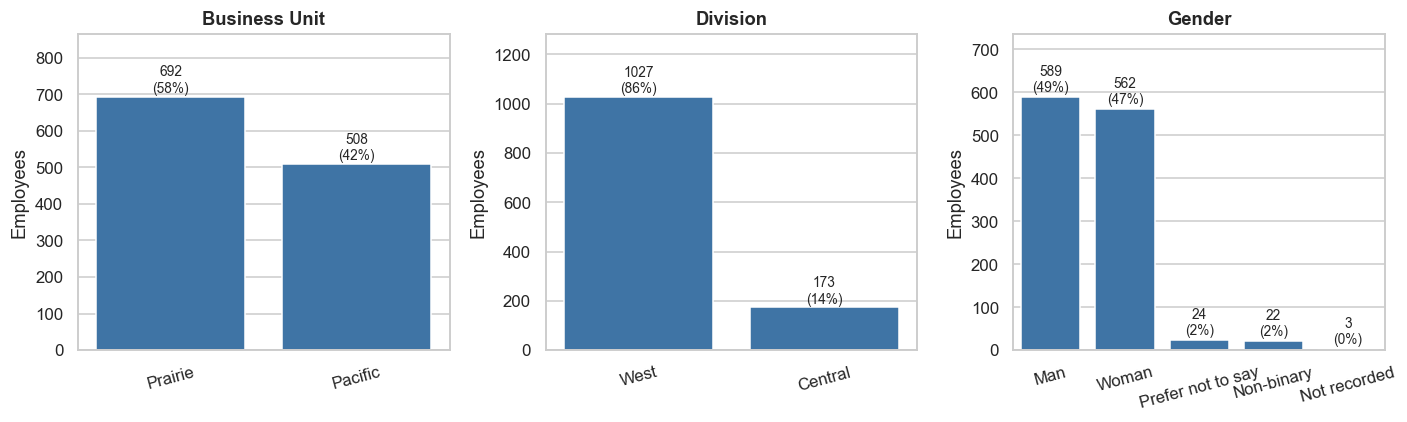

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, title in zip(axes, ["BusinessUnit", "Division", "Gender"],
                          ["Business Unit", "Division", "Gender"]):
    vc = df[col].value_counts()
    sns.barplot(x=vc.index.astype(str), y=vc.values, ax=ax, color="#2E75B6")
    for i, v in enumerate(vc.values):
        ax.text(i, v + 5, f"{v}\n({v/len(df)*100:.0f}%)", ha="center", va="bottom", fontsize=9)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("Employees")
    ax.set_ylim(0, vc.max() * 1.25)
    ax.tick_params(axis="x", rotation=15)
save(fig, "04_business_unit_division_gender"); plt.show()

**Interpretation: business unit, division and gender.**
The **Prairie** business unit has 692 employees (58%) and **Pacific** 508 (42%). By division, **West** holds 86% of staff and **Central** only 14% (Manitoba and Saskatchewan stores). Gender is evenly balanced overall:
49% men, 47% women, with 2% non-binary and 2% preferring not to say.

### 3.5 Gender by department and job title

In [32]:
gender_dept = pd.crosstab(df.Department, df.Gender, normalize="index").mul(100).round(1)
gender_dept

Gender,Man,Non-binary,Not recorded,Prefer not to say,Woman
Department,,,,,
Customer Service,50.3,2.6,0.0,1.0,46.1
Human Resources,42.6,2.9,0.0,1.5,52.9
Inventory,51.3,1.3,0.0,2.6,44.7
Management,48.1,1.6,0.8,0.0,49.6
Operations,46.8,1.4,0.0,2.2,49.6
Sales,49.4,1.8,0.4,2.7,45.6


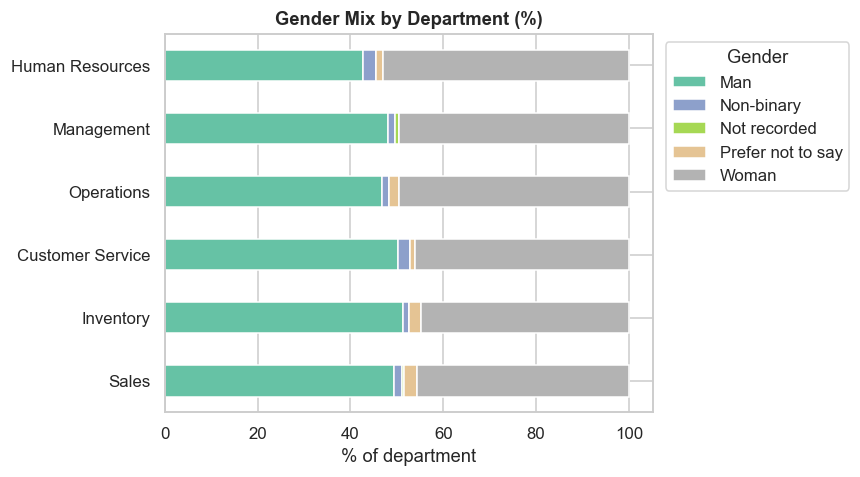

In [33]:
fig, ax = plt.subplots(figsize=(8, 4.5))
gender_dept.loc[df.Department.value_counts().index].plot(kind="barh", stacked=True, ax=ax,
                                                          colormap="Set2")
ax.set_title("Gender Mix by Department (%)")
ax.set_xlabel("% of department"); ax.set_ylabel("")
ax.legend(title="Gender", bbox_to_anchor=(1.01, 1), loc="upper left")
save(fig, "05_gender_by_department"); plt.show()

**Interpretation: gender by department.**
Women and men are close to parity in every department. The widest gap is in **HR (53% women versus 43% men)**; Inventory and Customer Service lean slightly male (about 51% and 50%). There is no department where one gender dominates,
so gender balance is not a staffing concern in this dataset.

### 3.6 Are there staffing imbalances? Department mix per store (Chart 6)

In [34]:
store_dept = pd.crosstab(df.Store, df.Department)
store_dept["Total"] = store_dept.sum(axis=1)
store_dept

Department,Customer Service,Human Resources,Inventory,Management,Operations,Sales,Total
Store,,,,,,,
Brandon (ST09),1,3,4,3,5,24,40
Calgary (ST01),33,15,45,23,25,84,225
Edmonton (ST02),45,9,37,20,27,65,203
Kelowna (ST07),11,8,18,12,7,37,93
Red Deer (ST03),15,4,15,9,13,35,91
Regina (ST10),6,0,4,2,3,15,30
Saskatoon (ST11),1,2,6,2,4,7,22
Surrey (ST05),19,9,34,23,16,51,152
Vancouver (ST04),34,6,35,19,27,66,187


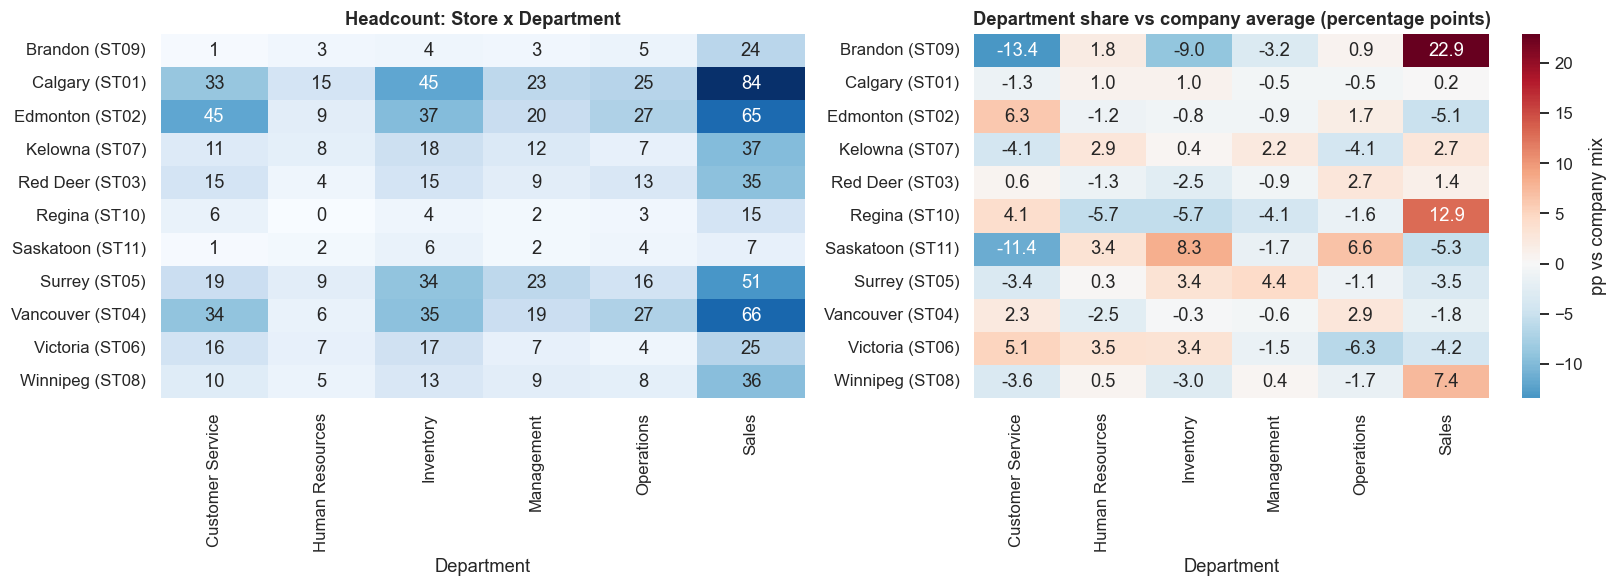

In [35]:
# Share of each store's staff in each department (row %). Compare each cell to the company-wide share
mix = pd.crosstab(df.Store, df.Department, normalize="index").mul(100)
company = df.Department.value_counts(normalize=True).mul(100)
gap = mix - company          # percentage-point gap vs company average

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(store_dept.drop(columns="Total"), annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("Headcount: Store x Department"); axes[0].set_ylabel("")
sns.heatmap(gap.round(1), annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=axes[1],
            cbar_kws={"label": "pp vs company mix"})
axes[1].set_title("Department share vs company average (percentage points)"); axes[1].set_ylabel("")
save(fig, "06_store_department_heatmap"); plt.show()

**Interpretation: department mix by store (are there imbalances?).**
Most large stores follow the company-wide mix closely (gaps within a few percentage points). The imbalances are in the **small Prairie and Central stores**:
**Brandon is 60% Sales (23 points above the company mix) with only one Customer Service employee**, **Saskatoon also has just one Customer Service employee**, and **Regina has no HR staff**. Edmonton is relatively Customer Service-heavy (45 people).
These patterns suggest uneven coverage that deserves a check against actual customer demand.

In [36]:
# Staffing structure per store: supervision span and employees per manager
mgmt_titles = ["Store Manager", "Assistant Store Manager"]
supv = df[df.JobTitle.str.contains("Supervisor", na=False)]
struct = pd.DataFrame({
    "Headcount": df.groupby("Store", observed=True).size(),
    "Managers (Store+Asst)": df[df.JobTitle.isin(mgmt_titles)].groupby("Store", observed=True).size(),
    "Supervisors": supv.groupby("Store", observed=True).size(),
    "Full-time %": df.groupby("Store", observed=True)["EmploymentType"].apply(lambda s: (s == "Full-time").mean() * 100),
    "Avg scheduled hrs": df.groupby("Store", observed=True)["ScheduledHours2025"].mean(),
}).fillna(0)
struct["Staff per manager"] = (struct["Headcount"] / struct["Managers (Store+Asst)"].replace(0, np.nan)).round(1)
struct["Staff per supervisor"] = (struct["Headcount"] / struct["Supervisors"].replace(0, np.nan)).round(1)
struct.sort_values("Headcount", ascending=False).round(1)

,Headcount,Managers (Store+Asst),Supervisors,Full-time %,Avg scheduled hrs,Staff per manager,Staff per supervisor
Store,,,,,,,
Calgary (ST01),225,23,60,73.8,1862.3,9.8,3.8
Edmonton (ST02),203,20,60,71.4,1848.4,10.2,3.4
Vancouver (ST04),187,19,51,71.7,1848.1,9.8,3.7
Surrey (ST05),152,23,40,77.0,1890.5,6.6,3.8
Kelowna (ST07),93,12,24,60.2,1755.7,7.8,3.9
Red Deer (ST03),91,9,27,68.1,1843.4,10.1,3.4
Winnipeg (ST08),81,9,27,80.2,1952.9,9.0,3.0
Victoria (ST06),76,7,16,69.7,1824.1,10.9,4.8
Brandon (ST09),40,3,16,72.5,1856.4,13.3,2.5


**Interpretation: supervision and management structure.**
Staff per supervisor is about 3 to 4 in most stores, but **Saskatoon has 7.3 staff per supervisor (only 3 supervisors for 22 people)**, double the norm, while Brandon (2.5) and Regina (2.1) are the opposite, with very dense supervision.
Staff per manager ranges from 6.6 in Surrey to 15 in Regina. These ratios are indicative only, because the "Store Manager" title count (58) is higher than the number of stores (11).

In [37]:
# Capacity view: total scheduled hours per store (a better "size" measure than headcount, since part-timers differ)
cap = df.groupby("Store", observed=True).agg(Headcount=("RecordID", "size"),
                                              ScheduledHours=("ScheduledHours2025", "sum"))
cap["FTE (hours / 2080)"] = (cap.ScheduledHours / 2080).round(1)
cap["Headcount per FTE"] = (cap.Headcount / cap["FTE (hours / 2080)"]).round(2)
cap.sort_values("FTE (hours / 2080)", ascending=False)

,Headcount,ScheduledHours,FTE (hours / 2080),Headcount per FTE
Store,,,,
Calgary (ST01),225,419016,201.4,1.12
Edmonton (ST02),203,375232,180.4,1.13
Vancouver (ST04),187,345592,166.2,1.13
Surrey (ST05),152,287352,138.2,1.10
Red Deer (ST03),91,167752,80.6,1.13
Kelowna (ST07),93,163280,78.5,1.18
Winnipeg (ST08),81,158184,76.0,1.07
Victoria (ST06),76,138632,66.6,1.14
Brandon (ST09),40,74256,35.7,1.12


**Interpretation: capacity (FTE).**
Measured in full-time equivalents rather than heads, store sizes keep the same order (Calgary about 201 FTE, Saskatoon about 20 FTE). Headcount per FTE is similar across stores (1.07 to 1.18), so **part-time use is not a major source of
imbalance**; Kelowna has the most part-time staff (40% part-time).

# PHASE 4: Tenure & Age Structure (Business Question 2)

### 4.1 Age and length-of-service distributions (Charts 7 and 8)

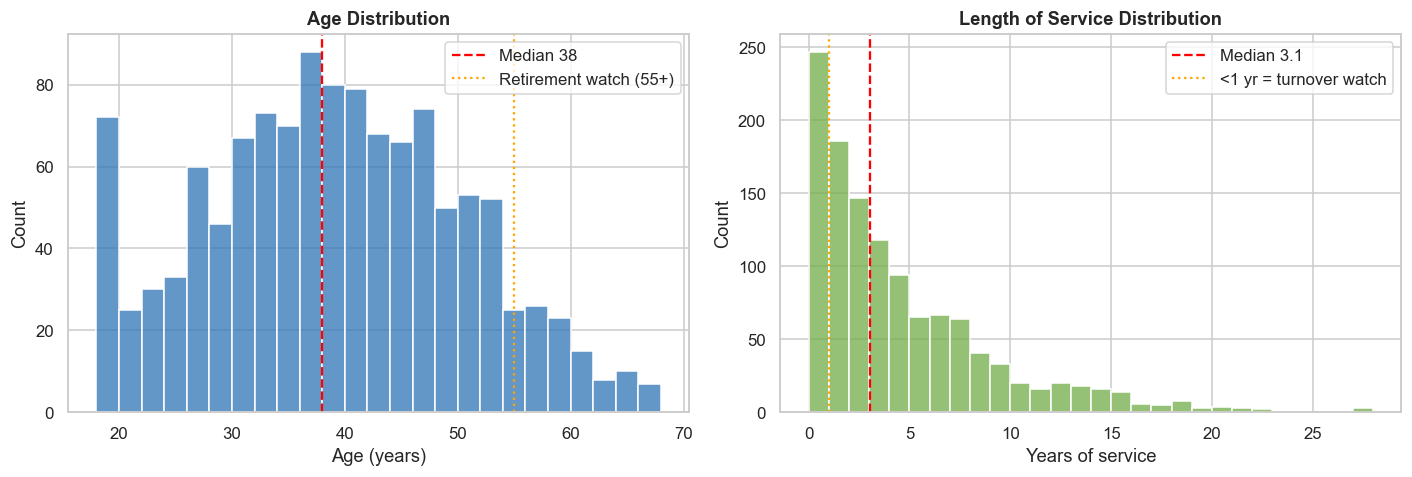

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df.AgeYears, bins=range(int(df.AgeYears.min()), int(df.AgeYears.max()) + 3, 2),
             color="#2E75B6", ax=axes[0])
axes[0].axvline(df.AgeYears.median(), color="red", ls="--", label=f"Median {df.AgeYears.median():.0f}")
axes[0].axvline(RETIRE_NEAR, color="orange", ls=":", label=f"Retirement watch ({RETIRE_NEAR}+)")
axes[0].set_title("Age Distribution"); axes[0].set_xlabel("Age (years)"); axes[0].legend()

sns.histplot(df.LengthOfServiceYears, bins=range(0, int(df.LengthOfServiceYears.max()) + 2, 1),
             color="#70AD47", ax=axes[1])
axes[1].axvline(df.LengthOfServiceYears.median(), color="red", ls="--",
                label=f"Median {df.LengthOfServiceYears.median():.1f}")
axes[1].axvline(TURNOVER_YRS, color="orange", ls=":", label=f"<{TURNOVER_YRS} yr = turnover watch")
axes[1].set_title("Length of Service Distribution"); axes[1].set_xlabel("Years of service"); axes[1].legend()
save(fig, "07_age_and_tenure_histograms"); plt.show()

**Interpretation: age and tenure distributions.**
**Age** is roughly bell-shaped around 38, with about half of employees between 30 and 47 and a thin tail above 55. The workforce is neither very young nor ageing.
**Length of service** is right-skewed: the bulk of staff have under 6.5 years, a quarter have under 1.2 years, and only about 11% have 10+ years. The company relies on a relatively **recent workforce with a small experienced core**.
(Part of the spike near zero comes from the placeholder hire dates; see the sensitivity check below.)

In [39]:
print(df.AgeBand.value_counts().sort_index().to_frame("Headcount").assign(**{"Share %": lambda d: (d.Headcount / len(df) * 100).round(1)}))
print()
print(df.TenureBand.value_counts().sort_index().to_frame("Headcount").assign(**{"Share %": lambda d: (d.Headcount / len(df) * 100).round(1)}))

         Headcount  Share %
AgeBand                    
18-24          143     11.9
25-34          301     25.1
35-44          373     31.1
45-54          284     23.7
55-59           59      4.9
60+             40      3.3

            Headcount  Share %
TenureBand                    
<1 yr             247     20.6
1-<3 yrs          333     27.8
3-<5 yrs          212     17.7
5-<10 yrs         270     22.5
10+ yrs           138     11.5


### 4.2 Are certain departments older/younger or more tenured? (Chart 9)

In [40]:
dept_age = df.groupby("Department", observed=True).agg(
    Headcount=("RecordID", "size"),
    Mean_age=("AgeYears", "mean"), Median_age=("AgeYears", "median"),
    Mean_tenure=("LengthOfServiceYears", "mean"), Median_tenure=("LengthOfServiceYears", "median"),
    Pct_55plus=("AgeYears", lambda s: (s >= RETIRE_NEAR).mean() * 100),
    Pct_under_1yr=("LengthOfServiceYears", lambda s: (s < TURNOVER_YRS).mean() * 100),
).round(1).sort_values("Mean_age", ascending=False)
dept_age

,Headcount,Mean_age,Median_age,Mean_tenure,Median_tenure,Pct_55plus,Pct_under_1yr
Department,,,,,,,
Operations,139,42.8,42.0,6.0,4.6,15.1,15.8
Human Resources,68,42.5,44.0,5.7,3.6,20.6,20.6
Inventory,228,41.7,41.5,6.1,4.5,11.4,11.8
Management,129,40.0,42.0,5.5,3.4,3.9,12.4
Sales,445,35.9,36.0,3.3,2.3,5.2,26.3
Customer Service,191,35.7,36.0,3.5,2.5,5.2,26.7


**Interpretation: age and tenure by department.**
**Operations (mean age 42.8), HR (42.5) and Inventory (41.7)** are the oldest and most tenured departments (about 6 years). **Sales and Customer Service are the youngest (about 36) and least tenured (about 3.3 to 3.5 years)**,
and a quarter or more of their staff have under a year of service. The front line is young and mobile; back-of-house functions are older and more stable.

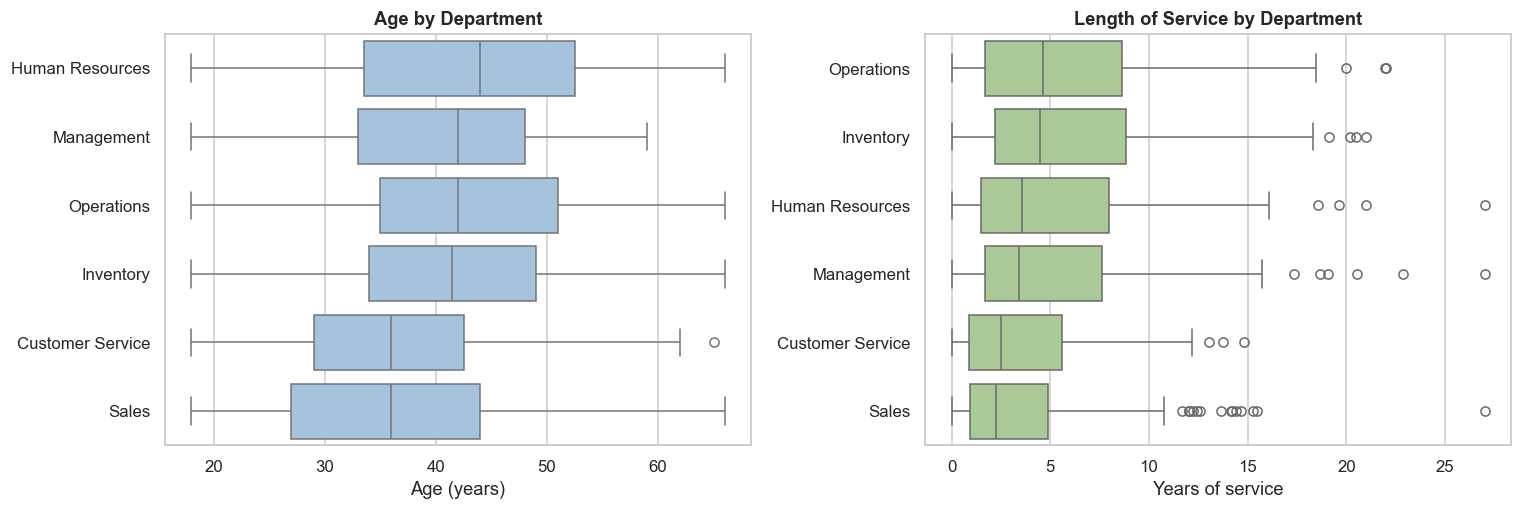

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
order = df.groupby("Department", observed=True).AgeYears.median().sort_values(ascending=False).index
sns.boxplot(data=df, y="Department", x="AgeYears", order=order, color="#9DC3E6", ax=axes[0])
axes[0].set_title("Age by Department"); axes[0].set_ylabel(""); axes[0].set_xlabel("Age (years)")
order = df.groupby("Department", observed=True).LengthOfServiceYears.median().sort_values(ascending=False).index
sns.boxplot(data=df, y="Department", x="LengthOfServiceYears", order=order, color="#A9D18E", ax=axes[1])
axes[1].set_title("Length of Service by Department"); axes[1].set_ylabel(""); axes[1].set_xlabel("Years of service")
save(fig, "08_age_tenure_by_department"); plt.show()

**Interpretation: boxplots by department.**
The boxes confirm the picture: age and service are higher and wider in Operations, HR and Inventory, and lower and tighter in Sales and Customer Service. The long upper whiskers on tenure in most departments show a few very long-serving employees
(up to 27 years), who hold valuable knowledge.

In [42]:
# Job titles: oldest, youngest, most and least tenured
title_age = df.groupby("JobTitle", observed=True).agg(
    Headcount=("RecordID", "size"), Mean_age=("AgeYears", "mean"),
    Mean_tenure=("LengthOfServiceYears", "mean"),
    Pct_55plus=("AgeYears", lambda s: (s >= RETIRE_NEAR).mean() * 100),
    Pct_under_1yr=("LengthOfServiceYears", lambda s: (s < TURNOVER_YRS).mean() * 100),
).round(1).sort_values("Mean_age", ascending=False)
title_age

,Headcount,Mean_age,Mean_tenure,Pct_55plus,Pct_under_1yr
JobTitle,,,,,
Operations Coordinator,65,43.5,5.6,12.3,15.4
HR Business Partner,40,42.9,5.2,25.0,15.0
Store Operations Supervisor,74,42.2,6.3,17.6,16.2
HR Coordinator,28,41.9,6.5,14.3,28.6
Inventory Supervisor,71,41.9,6.5,11.3,8.5
Stock Associate,71,41.9,6.4,9.9,14.1
Inventory Clerk,86,41.4,5.5,12.8,12.8
Assistant Store Manager,71,40.6,6.1,4.2,12.7
Store Manager,58,39.2,4.6,3.4,12.1


In [43]:
# Stores: age and tenure profile
store_age = df.groupby("Store", observed=True).agg(
    Headcount=("RecordID", "size"),
    Mean_age=("AgeYears", "mean"), Mean_tenure=("LengthOfServiceYears", "mean"),
    Pct_55plus=("AgeYears", lambda s: (s >= RETIRE_NEAR).mean() * 100),
    Pct_under_1yr=("LengthOfServiceYears", lambda s: (s < TURNOVER_YRS).mean() * 100),
).round(1).sort_values("Mean_age", ascending=False)
store_age

,Headcount,Mean_age,Mean_tenure,Pct_55plus,Pct_under_1yr
Store,,,,,
Saskatoon (ST11),22,41.7,3.7,13.6,18.2
Surrey (ST05),152,39.9,5.0,10.5,17.1
Edmonton (ST02),203,39.2,4.4,8.4,20.7
Red Deer (ST03),91,38.9,4.2,7.7,17.6
Victoria (ST06),76,38.9,3.9,7.9,26.3
Kelowna (ST07),93,38.7,5.4,10.8,20.4
Calgary (ST01),225,38.2,4.3,8.0,21.3
Vancouver (ST04),187,38.2,4.8,9.6,19.3
Winnipeg (ST08),81,38.2,4.2,1.2,16.0


### 4.3 Retirement and turnover risk segments (Charts 10 and 11)

In [44]:
df["RetireRisk"] = np.select(
    [df.AgeYears >= RETIRE_HIGH, df.AgeYears >= RETIRE_NEAR],
    [f"High ({RETIRE_HIGH}+)", f"Watch ({RETIRE_NEAR}-{RETIRE_HIGH-1})"], default="Low")
df["TurnoverRisk"] = np.where(df.LengthOfServiceYears < TURNOVER_YRS, "Early-tenure (<1 yr)", "Established")

print(df.RetireRisk.value_counts().to_frame("Headcount").assign(**{"Share %": lambda d: (d.Headcount / len(df) * 100).round(1)}))
print()
print(df.TurnoverRisk.value_counts().to_frame("Headcount").assign(**{"Share %": lambda d: (d.Headcount / len(df) * 100).round(1)}))

               Headcount  Share %
RetireRisk                       
Low                 1101     91.8
Watch (55-59)         59      4.9
High (60+)            40      3.3

                      Headcount  Share %
TurnoverRisk                            
Established                 953     79.4
Early-tenure (<1 yr)        247     20.6


In [45]:

# Sensitivity: early-tenure share with and without the placeholder hire dates
real = df[~df["HireDatePlaceholder"]]
def pct_new(s): return (s < TURNOVER_YRS).mean() * 100

sens4 = pd.DataFrame({
    "All employees": df.groupby("Department", observed=True)["LengthOfServiceYears"].apply(pct_new),
    "Excluding placeholder dates": real.groupby("Department", observed=True)["LengthOfServiceYears"].apply(pct_new),
}).round(1)
sens4.loc["COMPANY"] = [pct_new(df.LengthOfServiceYears).round(1), pct_new(real.LengthOfServiceYears).round(1)]
print(f"Employees under 1 year: {int((df.LengthOfServiceYears < 1).sum())} with placeholders, "
      f"{int((real.LengthOfServiceYears < 1).sum())} without")
sens4


Employees under 1 year: 247 with placeholders, 192 without


,All employees,Excluding placeholder dates
Department,,
Customer Service,26.7,20.5
Human Resources,20.6,14.3
Inventory,11.8,11.1
Management,12.4,9.6
Operations,15.8,15.2
Sales,26.3,21.3
COMPANY,20.6,16.8



**Interpretation: retirement and turnover segments.**
**Retirement:** 99 employees (about 8%) are 55 or older, and 40 of them are 60 or older, so roughly one in twelve people could leave through retirement within about ten years. This is a modest, manageable exposure for the company as a whole,
but it is **concentrated** in HR (21% aged 55+), Operations (15%) and Inventory (11%), while Inventory carries the largest number of people (26).
**Turnover:** 247 employees (21%) have under one year of service, which signals heavy recent hiring or high churn. The sensitivity table shows that **55 of these have suspect hire dates**; excluding them the share is about **17%**, still high and
**highest in Customer Service (about 21%) and Sales (about 21%)**. Either way, the front-line departments are where the workforce is least settled.


In [46]:
# Which departments / job titles carry the retirement exposure (counts matter as well as %)
ret = df[df.AgeYears >= RETIRE_NEAR]
ret_dept = ret.groupby("Department", observed=True).size().rename("Age55plus").to_frame()
ret_dept["Dept headcount"] = df.groupby("Department", observed=True).size()
ret_dept["% of dept"] = (ret_dept.Age55plus / ret_dept["Dept headcount"] * 100).round(1)
ret_dept["Age60plus"] = df[df.AgeYears >= RETIRE_HIGH].groupby("Department", observed=True).size()
ret_dept = ret_dept.fillna(0).sort_values("Age55plus", ascending=False)
ret_dept

,Age55plus,Dept headcount,% of dept,Age60plus
Department,,,,
Inventory,26,228,11.4,12.0
Sales,23,445,5.2,8.0
Operations,21,139,15.1,8.0
Human Resources,14,68,20.6,9.0
Customer Service,10,191,5.2,3.0
Management,5,129,3.9,0.0


**Interpretation: where retirement exposure sits.**
In percentage terms, **HR (21% aged 55+)** and **Operations (15%)** are most exposed; in absolute terms **Inventory (26 people) and Sales (23)** have the most employees aged 55+. Among job titles,
**HR Business Partners (25% aged 55+)** and Store Operations Supervisors (18%) stand out. These are the roles where succession planning should start.

In [47]:
# Critical roles: store managers and assistant managers close to retirement
crit = df[df.JobTitle.isin(mgmt_titles) & (df.AgeYears >= RETIRE_NEAR)][
    ["EmployeeID", "Store", "JobTitle", "AgeYears", "LengthOfServiceYears"]].sort_values("AgeYears", ascending=False)
print("Managers / assistant managers aged", RETIRE_NEAR, "+:", len(crit))
crit

Managers / assistant managers aged 55 +: 5


,EmployeeID,Store,JobTitle,AgeYears,LengthOfServiceYears
193,ACE00194,Calgary (ST01),Store Manager,59,7.10
1168,ACE01169,Surrey (ST05),Store Manager,59,9.57
1040,ACE01041,Kelowna (ST07),Assistant Store Manager,58,5.31
308,ACE00309,Vancouver (ST04),Assistant Store Manager,57,19.04
507,ACE00508,Surrey (ST05),Assistant Store Manager,55,0.53


**Interpretation: critical roles near retirement.**
Only **5 store managers or assistant managers are aged 55 or older** (two Store Managers aged 59, in Calgary and Surrey). The leadership pipeline is relatively young, so retirement risk in management is small and easy to plan for.

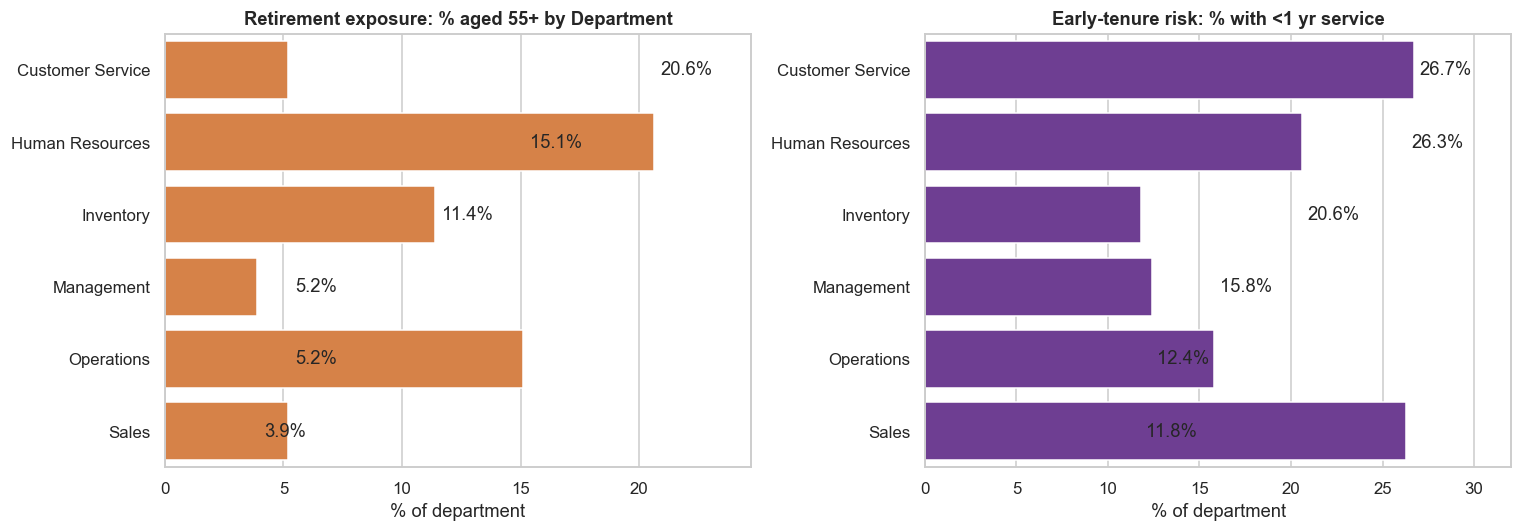

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
d = dept_age.sort_values("Pct_55plus", ascending=False)
sns.barplot(x=d.Pct_55plus, y=d.index, color="#ED7D31", ax=axes[0])
for i, v in enumerate(d.Pct_55plus):
    axes[0].text(v + 0.3, i, f"{v:.1f}%", va="center")
axes[0].set_title(f"Retirement exposure: % aged {RETIRE_NEAR}+ by Department"); axes[0].set_xlabel("% of department"); axes[0].set_ylabel("")
axes[0].set_xlim(0, d.Pct_55plus.max() * 1.2)

d = dept_age.sort_values("Pct_under_1yr", ascending=False)
sns.barplot(x=d.Pct_under_1yr, y=d.index, color="#7030A0", ax=axes[1])
for i, v in enumerate(d.Pct_under_1yr):
    axes[1].text(v + 0.3, i, f"{v:.1f}%", va="center")
axes[1].set_title(f"Early-tenure risk: % with <{TURNOVER_YRS} yr service"); axes[1].set_xlabel("% of department"); axes[1].set_ylabel("")
axes[1].set_xlim(0, d.Pct_under_1yr.max() * 1.2)
save(fig, "09_retirement_and_turnover_risk_by_dept"); plt.show()

**Interpretation: risk by department.**
The two charts show **opposite pictures**: retirement risk is highest in the back-of-house functions (HR, Operations, Inventory), while early-tenure (turnover) risk is highest in the front-line functions (Customer Service, Sales).
Different departments therefore need different people strategies: succession and knowledge transfer for the first group, and onboarding and retention for the second.

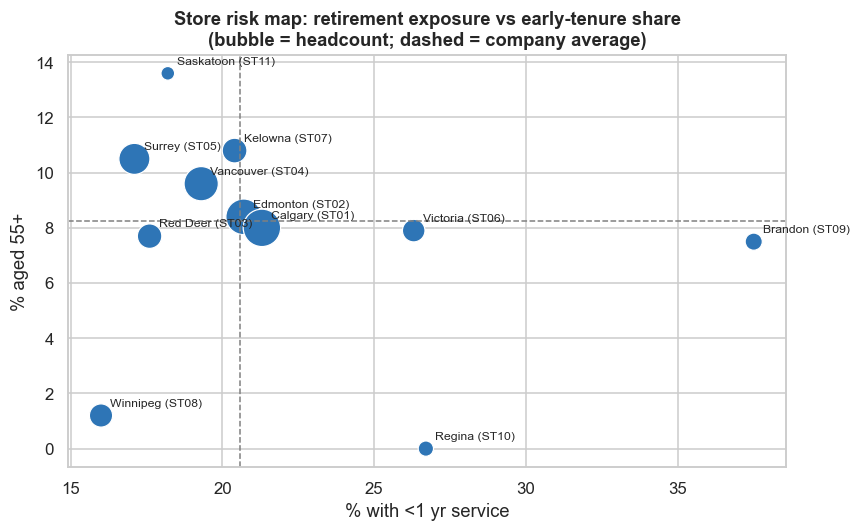

In [49]:
# Store-level hotspots for both risks
risk_store = store_age[["Headcount", "Pct_55plus", "Pct_under_1yr"]].sort_values("Pct_55plus", ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=risk_store, x="Pct_under_1yr", y="Pct_55plus", size="Headcount",
                sizes=(80, 600), color="#2E75B6", legend=False, ax=ax)
for s, r in risk_store.iterrows():
    ax.annotate(s, (r.Pct_under_1yr, r.Pct_55plus), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.axvline(df.TurnoverRisk.eq("Early-tenure (<1 yr)").mean() * 100, color="grey", ls="--", lw=1)
ax.axhline((df.AgeYears >= RETIRE_NEAR).mean() * 100, color="grey", ls="--", lw=1)
ax.set_title("Store risk map: retirement exposure vs early-tenure share\n(bubble = headcount; dashed = company average)")
ax.set_xlabel(f"% with <{TURNOVER_YRS} yr service"); ax.set_ylabel(f"% aged {RETIRE_NEAR}+")
save(fig, "10_store_risk_map"); plt.show()

**Interpretation: store risk map.**
Stores in the **top-left** have an older workforce but few new starters (Saskatoon, Surrey, Kelowna); stores to the **right** have lots of newcomers (**Brandon has 37.5% under one year of service**, Regina and Victoria about 26%).
Winnipeg and Regina have almost no retirement exposure. Saskatoon, Brandon and Regina are small, so one or two people change their percentages noticeably; treat them as signals to investigate, not as proven problems.

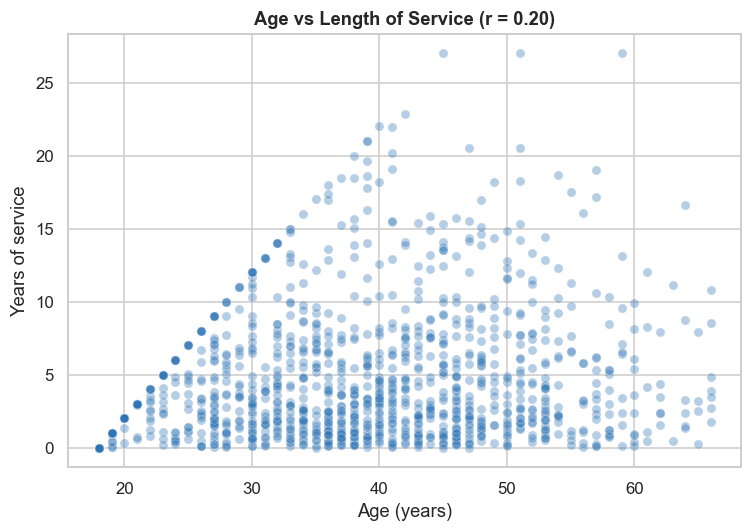

In [50]:
# Age vs tenure (does an older workforce mean longer service?)
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="AgeYears", y="LengthOfServiceYears", alpha=0.35, color="#2E75B6", ax=ax)
r = df[["AgeYears", "LengthOfServiceYears"]].corr().iloc[0, 1]
ax.set_title(f"Age vs Length of Service (r = {r:.2f})")
ax.set_xlabel("Age (years)"); ax.set_ylabel("Years of service")
save(fig, "11_age_vs_tenure"); plt.show()

**Interpretation: age versus length of service.**
Age and service are only **weakly related (r about 0.20)**: many older employees are relatively new to the company, and several younger ones have long service. This tells us that an older age is not a proxy for experience, and that
the company is hiring across all ages, which supports using age and tenure as **separate** risk lenses.

# PHASE 5: Absenteeism Analysis (Business Question 3)
Absence is measured in **absent hours in 2025** (`AbsentHours`). Because part-time staff are scheduled for fewer hours, we also
look at the **absence rate** (absent hours / scheduled hours) where it matters. The 2 employees with missing absence data are excluded here.

### 5.1 Overall distribution of absent hours

In [51]:
a = df.dropna(subset=["AbsentHours"]).copy()          # analysis set for absence (1,198 employees)
_, FENCE = iqr_bounds(a["AbsentHours"])               # IQR upper fence (extreme absence threshold)
a["HighAbsence"] = a["AbsentHours"] > FENCE

total_abs = a["AbsentHours"].sum()
top10 = a.nlargest(int(len(a) * 0.10), "AbsentHours")["AbsentHours"].sum()

abs_summary = pd.Series({
    "Employees analysed": len(a),
    "Mean absent hours": a.AbsentHours.mean(),
    "Median absent hours": a.AbsentHours.median(),
    "90th percentile": a.AbsentHours.quantile(.90),
    "99th percentile": a.AbsentHours.quantile(.99),
    "Maximum": a.AbsentHours.max(),
    "% with zero absence": (a.AbsentHours == 0).mean() * 100,
    "Company absence rate % (total absent / total scheduled)": total_abs / a.ScheduledHours2025.sum() * 100,
    "Total absent hours": total_abs,
    "Equivalent full-time staff absent all year (FTE)": total_abs / 2080,
    "% of all absent hours from the top 10% of employees": top10 / total_abs * 100,
    f"Employees above extreme-absence fence (> {FENCE:.0f} h)": int(a.HighAbsence.sum()),
    "% of all absent hours from those employees": a.loc[a.HighAbsence, "AbsentHours"].sum() / total_abs * 100,
}).round(2)
abs_summary.to_frame("Value")

,Value
Employees analysed,1198.00
Mean absent hours,46.73
Median absent hours,32.00
90th percentile,104.00
99th percentile,240.24
Maximum,720.00
% with zero absence,17.86
Company absence rate % (total absent / total scheduled),2.52
Total absent hours,55984.00
Equivalent full-time staff absent all year (FTE),26.92


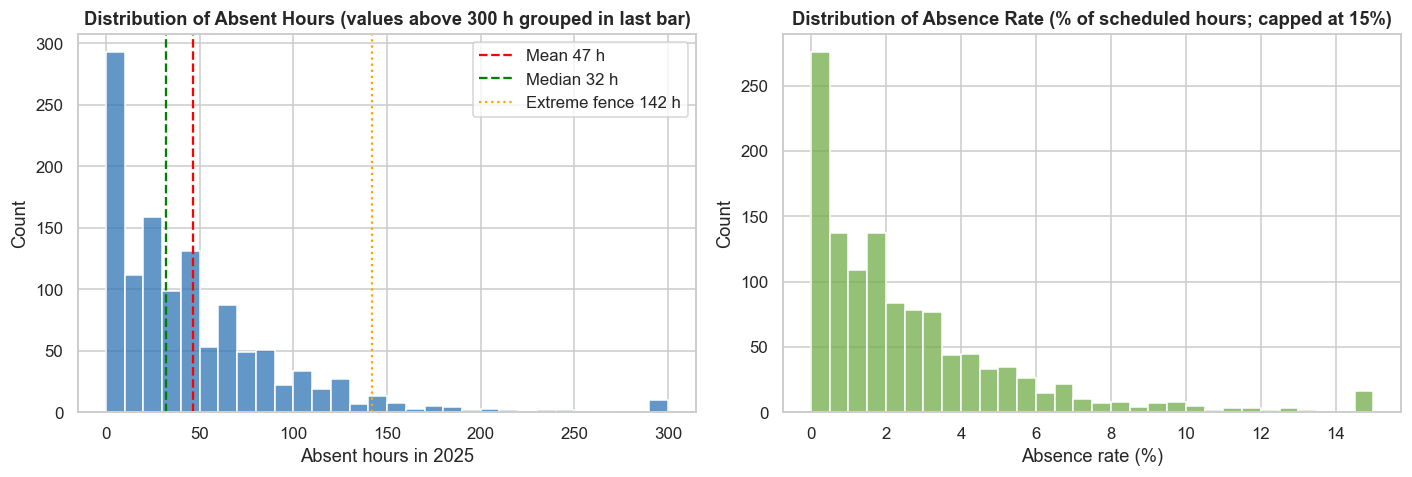

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
clip = 300
sns.histplot(a.AbsentHours.clip(upper=clip), bins=30, color="#2E75B6", ax=axes[0])
axes[0].axvline(a.AbsentHours.mean(), color="red", ls="--", label=f"Mean {a.AbsentHours.mean():.0f} h")
axes[0].axvline(a.AbsentHours.median(), color="green", ls="--", label=f"Median {a.AbsentHours.median():.0f} h")
axes[0].axvline(FENCE, color="orange", ls=":", label=f"Extreme fence {FENCE:.0f} h")
axes[0].set_title(f"Distribution of Absent Hours (values above {clip} h grouped in last bar)")
axes[0].set_xlabel("Absent hours in 2025"); axes[0].legend()

sns.histplot((a.AbsenceRate * 100).clip(upper=15), bins=30, color="#70AD47", ax=axes[1])
axes[1].set_title("Distribution of Absence Rate (% of scheduled hours; capped at 15%)")
axes[1].set_xlabel("Absence rate (%)")
save(fig, "12_absence_distribution"); plt.show()

**Interpretation: overall absence.**
Absence is **highly right-skewed**: the typical employee (median) misses 32 hours, about four working days, but the mean is 47 hours because a small group is absent for very long periods
(maximum 720 hours). About 18% of employees recorded no absence at all. The company-wide absence rate is roughly **2.5% of scheduled hours**, equal to about **27 full-time positions** absent for the whole year.
The top 10% of employees account for about **36%** of all absent hours, so a small group drives a large share of lost time. This is why we report **medians alongside means** from here on.

### 5.2 Which stores, departments, job titles and demographics show high absenteeism?

In [53]:
def absence_table(col, min_n=1):
    t = a.groupby(col, observed=True).agg(
        Employees=("RecordID", "size"),
        Mean_hours=("AbsentHours", "mean"),
        Median_hours=("AbsentHours", "median"),
        Pooled_rate_pct=("AbsentHours", "sum"),
        Pct_extreme=("HighAbsence", "mean"),
    )
    sched = a.groupby(col, observed=True)["ScheduledHours2025"].sum()
    t["Pooled_rate_pct"] = t["Pooled_rate_pct"] / sched * 100
    t["Pct_extreme"] = t["Pct_extreme"] * 100
    t = t[t.Employees >= min_n]
    return t.sort_values("Mean_hours", ascending=False).round(1)

for col in ["Department", "JobTitle", "Store", "Province", "Gender", "EmploymentType", "AgeBand", "TenureBand"]:
    print(f"\n=== Absence by {col} ===")
    print(absence_table(col).to_string())


=== Absence by Department ===
                  Employees  Mean_hours  Median_hours  Pooled_rate_pct  Pct_extreme
Department                                                                         
Customer Service        191        63.0          48.0              3.4          7.9
Sales                   443        57.4          40.0              3.1          7.0
Human Resources          68        46.7          32.0              2.5          2.9
Inventory               228        34.1          28.0              1.9          0.4
Management              129        30.5          24.0              1.6          0.8
Operations              139        26.2          20.0              1.4          0.0

=== Absence by JobTitle ===
                             Employees  Mean_hours  Median_hours  Pooled_rate_pct  Pct_extreme
JobTitle                                                                                      
Customer Service Supervisor         55        67.5          52.0              

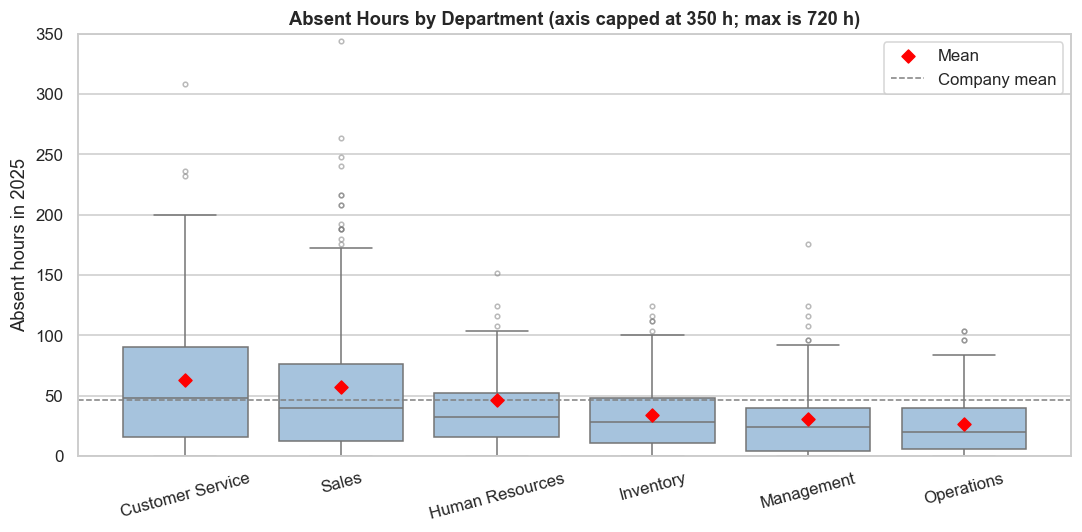

In [54]:
# Boxplot: absent hours by department (Chart 13)
order = a.groupby("Department", observed=True).AbsentHours.median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=a, x="Department", y="AbsentHours", order=order, color="#9DC3E6",
            flierprops=dict(marker="o", markersize=3, alpha=0.5), ax=ax)
means = a.groupby("Department", observed=True).AbsentHours.mean().reindex(order)
ax.scatter(range(len(order)), means.values, color="red", marker="D", zorder=5, label="Mean")
ax.axhline(a.AbsentHours.mean(), color="grey", ls="--", lw=1, label="Company mean")
ax.set_ylim(0, 350); ax.set_title("Absent Hours by Department (axis capped at 350 h; max is 720 h)")
ax.set_xlabel(""); ax.set_ylabel("Absent hours in 2025"); ax.legend()
plt.setp(ax.get_xticklabels(), rotation=15)
save(fig, "13_absence_boxplot_department"); plt.show()

**Interpretation: departments.**
Absence differs sharply by department (Kruskal-Wallis test, p < 0.001). **Customer Service** (mean 63 h, median 48 h) and **Sales** (mean 57 h, median 40 h) are the highest, while **Operations** (26 h), **Management** (30 h)
and **Inventory** (34 h) are the lowest, so the gap is more than 2x. Customer-facing floor roles miss about twice as many hours as back-of-house roles. Sales and Customer Service together make up 53% of
staff but generate about **67%** of all absent hours.

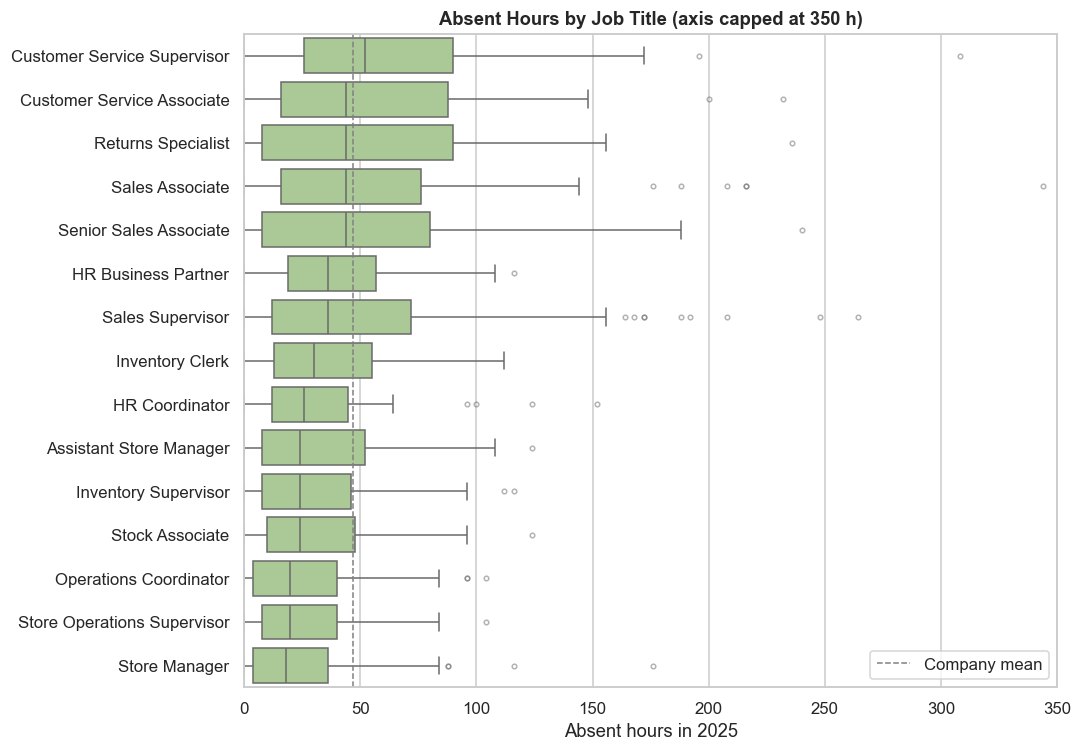

In [55]:
# Boxplot: absent hours by job title (Chart 14)
order = a.groupby("JobTitle", observed=True).AbsentHours.median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 7))
sns.boxplot(data=a, y="JobTitle", x="AbsentHours", order=order, color="#A9D18E",
            flierprops=dict(marker="o", markersize=3, alpha=0.5), ax=ax)
ax.axvline(a.AbsentHours.mean(), color="grey", ls="--", lw=1, label="Company mean")
ax.set_xlim(0, 350); ax.set_title("Absent Hours by Job Title (axis capped at 350 h)")
ax.set_ylabel(""); ax.set_xlabel("Absent hours in 2025"); ax.legend()
save(fig, "14_absence_boxplot_job_title"); plt.show()

**Interpretation: job titles.**
The highest-absence roles are **Customer Service Supervisor** (mean 67 h, and 15% of them above the extreme-absence fence), **Customer Service Associate** (66 h) and the Sales roles (56 to 59 h).
The lowest are Store Operations Supervisor (25 h), Operations Coordinator (27 h) and Store Manager (28 h). Supervisors in Sales and Customer Service stand out as a **risk zone**: they are the people responsible for covering the shift
when others are absent, yet their own absence is high.

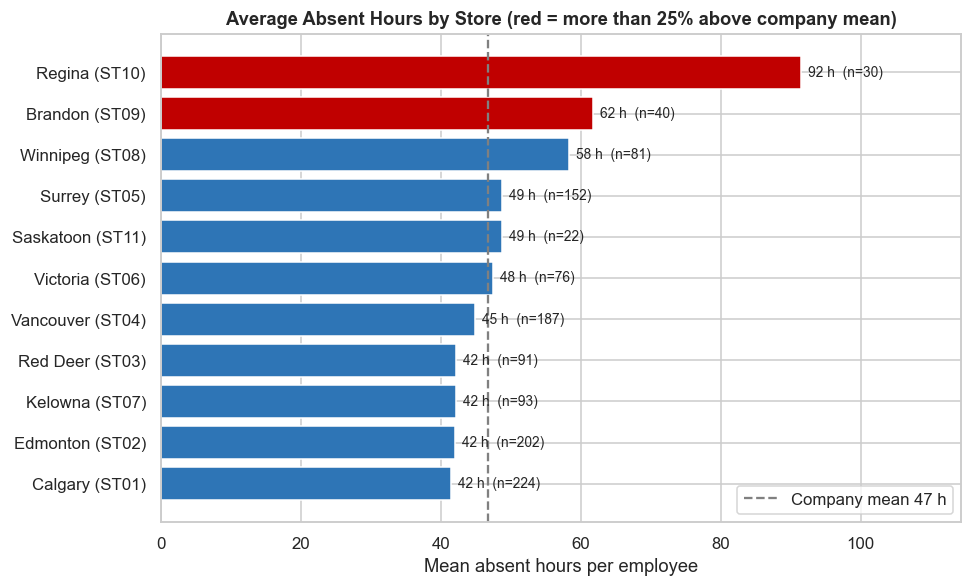

In [56]:
# Average absence by store (Chart 15)
st = absence_table("Store")
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ["#C00000" if v > a.AbsentHours.mean() * 1.25 else "#2E75B6" for v in st.Mean_hours]
ax.barh(st.index[::-1], st.Mean_hours[::-1], color=colors[::-1])
for i, (m, n) in enumerate(zip(st.Mean_hours[::-1], st.Employees[::-1])):
    ax.text(m + 1, i, f"{m:.0f} h  (n={n})", va="center", fontsize=9)
ax.axvline(a.AbsentHours.mean(), color="grey", ls="--", label=f"Company mean {a.AbsentHours.mean():.0f} h")
ax.set_title("Average Absent Hours by Store (red = more than 25% above company mean)")
ax.set_xlabel("Mean absent hours per employee"); ax.legend(loc="lower right")
ax.set_xlim(0, st.Mean_hours.max() * 1.25)
save(fig, "15_absence_by_store"); plt.show()

**Interpretation: stores.**
**Regina is the clear outlier**: 91 hours per employee, nearly **2x the company average**, with 20% of its staff above the extreme-absence fence. Brandon (62 h) and Winnipeg (58 h) follow.
The big Alberta stores (Calgary, Edmonton, Red Deer) are the *lowest* at about 41 to 42 h. At province level, **Saskatchewan (73 h) and Manitoba (59 h)** sit well above Alberta (42 h) and BC (46 h), so the problem is concentrated in the
Prairie / Central smaller stores. Caution: Regina has only 30 employees, so one or two long-term absences can move its average; the department-adjusted view in 5.5 tests this properly.

### 5.3 Correlations: age, length of service, department and store

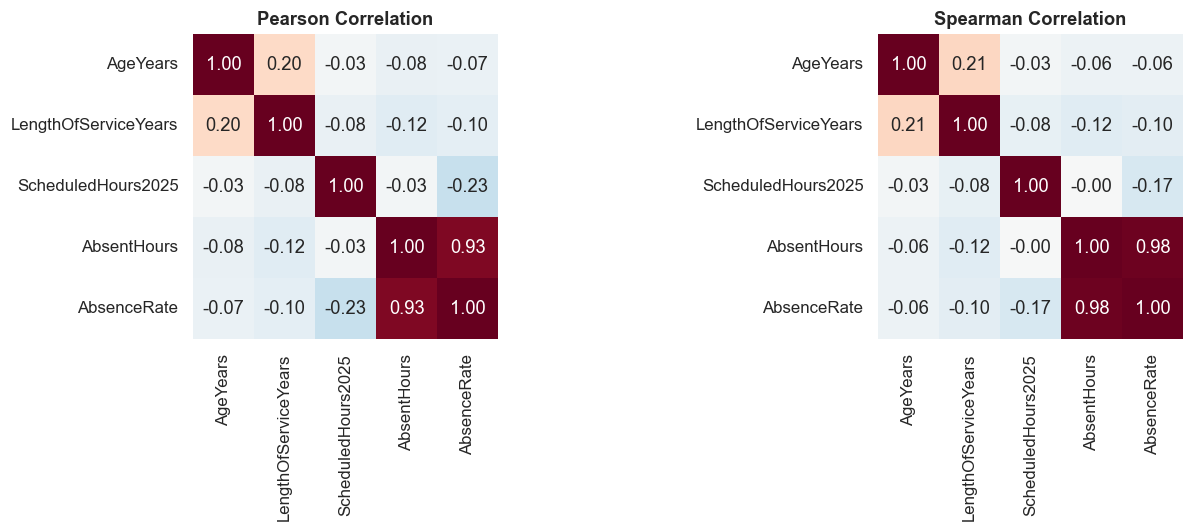

In [57]:
num = ["AgeYears", "LengthOfServiceYears", "ScheduledHours2025", "AbsentHours", "AbsenceRate"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(a[num].corr(method=method), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                square=True, cbar=False, ax=ax)
    ax.set_title(f"{method.title()} Correlation")
save(fig, "16_correlation_heatmap"); plt.show()

**Interpretation: correlations.**
Age and absence are almost uncorrelated (**r = -0.06 to -0.08**), and length of service has a weak **negative** link (**r = -0.12**): longer-serving staff are absent slightly less. These effects are statistically detectable
but very small, so **age and tenure alone do not explain absenteeism**. The strong correlation between hours and rate (0.93 to 0.98) is expected, because the rate is built from the hours. Scheduled hours relate negatively to the *rate* (-0.23) because
part-time employees have a smaller denominator.

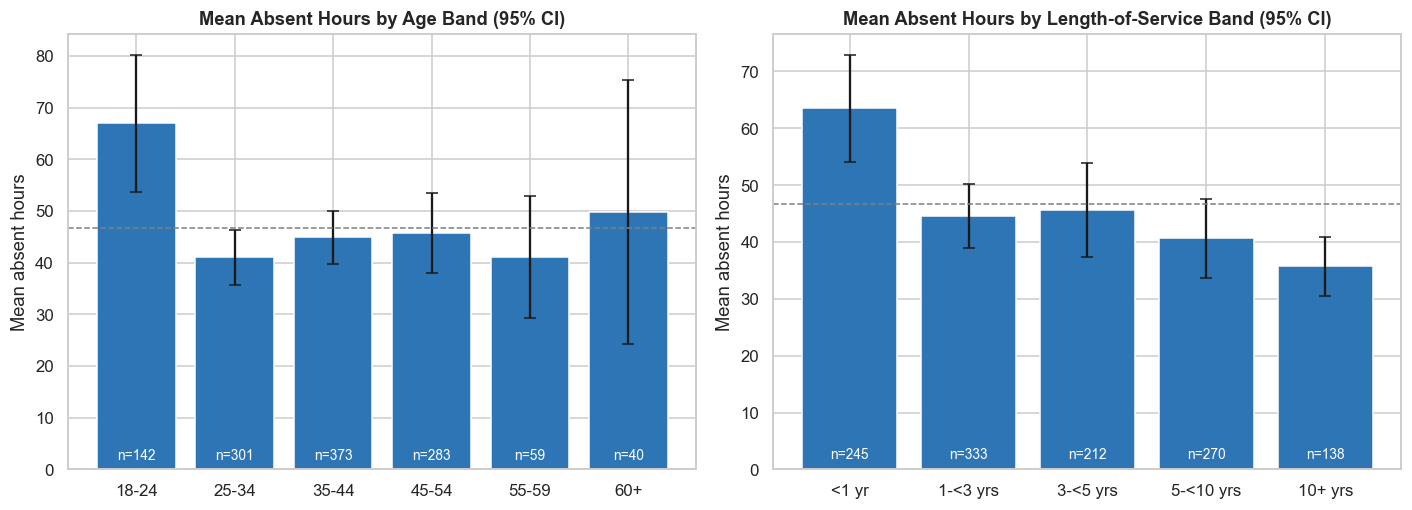

In [58]:
# Absence by age band and tenure band with 95% confidence intervals (Chart 17)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col, title in zip(axes, ["AgeBand", "TenureBand"], ["Age Band", "Length-of-Service Band"]):
    g = a.groupby(col, observed=True).AbsentHours.agg(["mean", "std", "count"])
    g["ci"] = 1.96 * g["std"] / np.sqrt(g["count"])
    ax.bar(g.index.astype(str), g["mean"], yerr=g["ci"], capsize=4, color="#2E75B6")
    ax.axhline(a.AbsentHours.mean(), color="grey", ls="--", lw=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
        ax.text(i, 2, f"n={n}", ha="center", color="white", fontsize=9)
    ax.set_title(f"Mean Absent Hours by {title} (95% CI)"); ax.set_ylabel("Mean absent hours"); ax.set_xlabel("")
save(fig, "17_absence_by_age_and_tenure"); plt.show()

**Interpretation: age and tenure bands.**
Two segments stand out: **employees aged 18 to 24 (mean 67 h)** and **employees with under 1 year of service (mean 63 h)**, against a company mean of 47 h. After 1 year of service absence settles at
about 36 to 46 h and keeps falling to 36 h for staff with 10+ years. Older workers (55+) are **not** more absent than average. This pattern points to an **onboarding and early-career engagement** issue rather than an ageing issue.

### 5.4 Are the differences statistically real?

In [59]:
from scipy import stats

rows = []
for col in ["Department", "JobTitle", "Store", "Province", "AgeBand", "TenureBand", "Gender", "EmploymentType"]:
    groups = [g.AbsentHours.values for _, g in a.groupby(col, observed=True) if len(g) >= 5]
    H, p = stats.kruskal(*groups)
    k, n = len(groups), sum(len(g) for g in groups)
    eps2 = max((H - k + 1) / (n - k), 0)          # epsilon-squared effect size
    rows.append({"Factor": col, "Groups": k, "H statistic": round(H, 1), "p-value": p,
                 "Effect size (eps^2)": round(eps2, 3),
                 "Significant (p<0.05)": "Yes" if p < 0.05 else "No"})
tests = pd.DataFrame(rows).sort_values("Effect size (eps^2)", ascending=False)
tests["p-value"] = tests["p-value"].apply(lambda v: f"{v:.2g}")
print(tests.to_string(index=False))

for col in ["AgeYears", "LengthOfServiceYears"]:
    r, p = stats.spearmanr(a[col], a["AbsentHours"])
    print(f"\nSpearman {col} vs AbsentHours: rho = {r:.3f}, p = {p:.3g}")

        Factor  Groups  H statistic p-value  Effect size (eps^2) Significant (p<0.05)
    Department       6         65.6 8.4e-13                0.051                  Yes
      JobTitle      15         69.7 2.2e-09                0.047                  Yes
    TenureBand       5         20.1 0.00047                0.014                  Yes
      Province       4         15.2  0.0016                0.010                  Yes
         Store      11         18.9   0.041                0.008                  Yes
       AgeBand       6         14.5   0.012                0.008                  Yes
        Gender       4          1.5    0.68                0.000                   No
EmploymentType       2          0.0    0.86                0.000                   No

Spearman AgeYears vs AbsentHours: rho = -0.062, p = 0.0321

Spearman LengthOfServiceYears vs AbsentHours: rho = -0.124, p = 1.7e-05


**Interpretation: significance tests.**
Because absence is heavily skewed we use non-parametric tests (Kruskal-Wallis). **Department, job title and tenure band** show the strongest and most significant differences (p < 0.001), followed by province, age band and store (p < 0.05).
**Gender and employment type show no significant difference** (p = 0.68 and 0.86): men and women, and full-time and part-time staff, are absent for similar hours. Effect sizes are small to moderate, so these factors
*shift* the averages but no single characteristic predicts an individual's absence. That is why the strategy should target **groups and conditions** (department, new hires, specific stores), not stereotypes about individuals.

### 5.5 Is it the store, or the mix of departments in the store? (confounding check)

In [60]:
# Expected absence for each store if every department behaved like the company-wide department average
dept_mean = a.groupby("Department", observed=True).AbsentHours.mean()
a["ExpectedByDept"] = a["Department"].map(dept_mean).astype(float)

adj = a.groupby("Store", observed=True).agg(Employees=("RecordID", "size"),
                                            Observed=("AbsentHours", "mean"),
                                            Expected=("ExpectedByDept", "mean"))
adj["Gap_hours"] = adj.Observed - adj.Expected
adj["Excess_hours_total"] = adj.Gap_hours * adj.Employees
adj = adj.sort_values("Gap_hours", ascending=False).round(1)
adj

,Employees,Observed,Expected,Gap_hours,Excess_hours_total
Store,,,,,
Regina (ST10),30,91.5,50.5,41.0,1229.2
Brandon (ST09),40,61.8,48.5,13.3,532.6
Winnipeg (ST08),81,58.3,47.6,10.7,867.0
Saskatoon (ST11),22,48.7,42.2,6.5,143.3
Surrey (ST05),152,48.8,44.9,3.9,599.4
Victoria (ST06),76,47.5,48.3,-0.8,-59.8
Vancouver (ST04),187,44.9,46.5,-1.6,-302.2
Kelowna (ST07),93,42.2,46.8,-4.6,-429.4
Red Deer (ST03),91,42.2,46.9,-4.7,-427.0


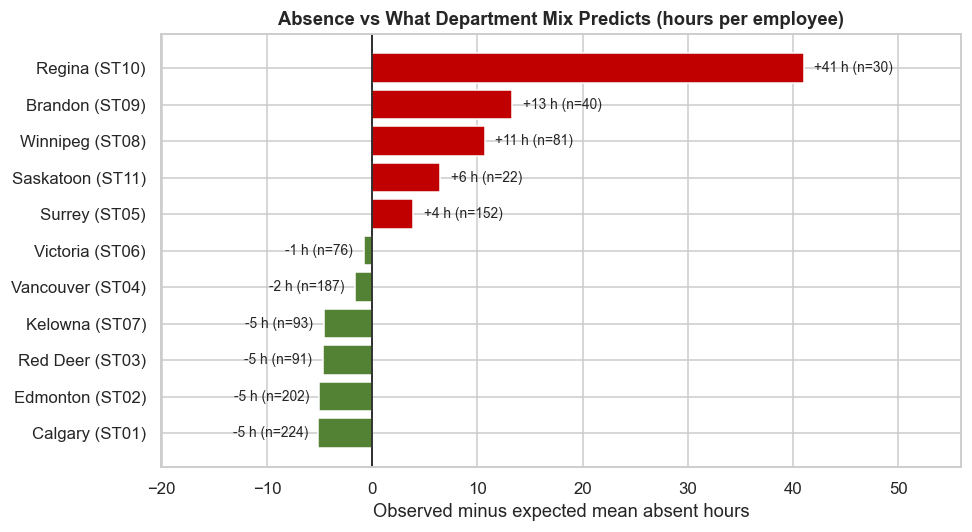

In [61]:
fig, ax = plt.subplots(figsize=(9, 5))
d = adj.sort_values("Gap_hours")
ax.barh(d.index, d.Gap_hours, color=["#C00000" if v > 0 else "#548235" for v in d.Gap_hours])
for i, (g, n) in enumerate(zip(d.Gap_hours, d.Employees)):
    ax.text(g + (1 if g >= 0 else -1), i, f"{g:+.0f} h (n={n})", va="center",
            ha="left" if g >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", lw=1)
ax.set_title("Absence vs What Department Mix Predicts (hours per employee)")
ax.set_xlabel("Observed minus expected mean absent hours")
ax.set_xlim(d.Gap_hours.min() - 15, d.Gap_hours.max() + 15)
save(fig, "18_store_absence_gap_vs_expected"); plt.show()

**Interpretation: store effect after adjusting for department mix.**
Part of a store's absence is explained by *which departments it has* (Sales and Customer Service naturally miss more hours). After removing that, **Regina still runs about 41 hours per employee above expectation**, Brandon about +13 and
Winnipeg about +11, so those are genuine store-level issues rather than a department-mix effect. Calgary, Edmonton, Red Deer and Kelowna come in about 5 hours *below* expectation, a sign of better practice
that could be shared. Again, Regina, Brandon and Saskatoon are small, so treat the size of the gaps with caution.

In [62]:
# Does the "young" and "new hire" effect survive inside each department?
a["Under25"] = np.where(a.AgeYears < 25, "Under 25", "25+")
a["NewHire"] = np.where(a.LengthOfServiceYears < 1, "<1 yr service", "1+ yr service")

print("Mean absent hours: age group within department")
print(a.pivot_table(index="Department", columns="Under25", values="AbsentHours", aggfunc=["mean", "count"], observed=True).round(1))
print("\nMean absent hours: new hires within department")
print(a.pivot_table(index="Department", columns="NewHire", values="AbsentHours", aggfunc=["mean", "count"], observed=True).round(1))

Mean absent hours: age group within department
                  mean          count         
Under25            25+ Under 25   25+ Under 25
Department                                    
Customer Service  61.5     71.3   162       29
Human Resources   35.4    112.0    58       10
Inventory         34.7     23.7   216       12
Management        29.8     36.6   116       13
Operations        25.7     38.0   133        6
Sales             54.1     74.1   371       72

Mean absent hours: new hires within department
                          mean                       count              
NewHire          1+ yr service <1 yr service 1+ yr service <1 yr service
Department                                                              
Customer Service          62.4          64.5           140            51
Human Resources           44.1          56.9            54            14
Inventory                 35.1          26.8           201            27
Management                26.8          56.8


**Interpretation: do age and tenure still matter inside a department?**
Yes, partly. In **Sales**, staff with under 1 year of service average about **80 h versus 49 h** for established staff, and under-25s average 74 h versus 54 h. In **Customer Service** the new-hire and young effects are smaller (64 h versus 62 h; 71 h versus 62 h).
In Inventory the pattern even reverses. So the early-tenure problem is mainly a **Sales-floor issue**, while Customer Service is high for *everyone*. Small groups (for example 10 under-25s in HR) are too small to read much into.


In [63]:

# Sensitivity: is the new-hire effect still there once placeholder hire dates are removed?
placeholder = a[a.HireDatePlaceholder]
genuine_new = a[(~a.HireDatePlaceholder) & (a.LengthOfServiceYears < 1)]
established = a[a.LengthOfServiceYears >= 1]

new_vs_est = pd.DataFrame({
    "Employees": [len(placeholder), len(genuine_new), len(established)],
    "Mean absent hours": [placeholder.AbsentHours.mean(), genuine_new.AbsentHours.mean(), established.AbsentHours.mean()],
    "Median absent hours": [placeholder.AbsentHours.median(), genuine_new.AbsentHours.median(), established.AbsentHours.median()],
}, index=["Placeholder hire dates (suspect)", "Genuine new hires (under 1 yr)", "Established (1+ yr)"]).round(1)
print(new_vs_est)

x = a[a.Department == "Sales"]
print("\nSales only (mean absent hours):")
print({"Genuine new hires": round(x[(~x.HireDatePlaceholder) & (x.LengthOfServiceYears < 1)].AbsentHours.mean(), 1),
       "Established": round(x[x.LengthOfServiceYears >= 1].AbsentHours.mean(), 1)})
new_vs_est


                                  Employees  Mean absent hours  Median absent hours
Placeholder hire dates (suspect)         54               77.9                 56.0
Genuine new hires (under 1 yr)          191               59.4                 40.0
Established (1+ yr)                     953               42.4                 32.0

Sales only (mean absent hours):
{'Genuine new hires': np.float64(78.3), 'Established': np.float64(49.4)}


,Employees,Mean absent hours,Median absent hours
Placeholder hire dates (suspect),54,77.9,56.0
Genuine new hires (under 1 yr),191,59.4,40.0
Established (1+ yr),953,42.4,32.0



**Interpretation: robustness to the suspect hire dates.**
The 54 employees with placeholder hire dates are absent even more than average (78 h), so they *add* to the early-tenure effect, but the finding does not depend on them. **Genuine new hires average 59 h versus 42 h for established staff**
(about 17 hours more), and in Sales the gap is about **78 h versus 49 h**. The early-tenure absence pattern is real; it is just somewhat smaller than the raw table suggests. Confirming the true hire dates with the client would sharpen all tenure results.


In [64]:
# Sensitivity: how much do the extreme-absence employees move the averages?
with_out = a.groupby("Department", observed=True).AbsentHours.mean()
without = a[~a.HighAbsence].groupby("Department", observed=True).AbsentHours.mean()
sens = pd.DataFrame({"Mean (all)": with_out, "Mean (excl. extreme)": without,
                     "Median (all)": a.groupby("Department", observed=True).AbsentHours.median()}).round(1)
sens["Ranking changes?"] = np.where(sens["Mean (all)"].rank() == sens["Mean (excl. extreme)"].rank(), "No", "Yes")
print(f"Company mean: {a.AbsentHours.mean():.1f} h with extreme cases, {a.loc[~a.HighAbsence,'AbsentHours'].mean():.1f} h without")
sens

Company mean: 46.7 h with extreme cases, 38.3 h without


,Mean (all),Mean (excl. extreme),Median (all),Ranking changes?
Department,,,,
Customer Service,63.0,49.8,48.0,No
Human Resources,46.7,36.7,32.0,No
Inventory,34.1,32.4,28.0,No
Management,30.5,29.3,24.0,No
Operations,26.2,26.2,20.0,No
Sales,57.4,43.9,40.0,No


**Interpretation: robustness.**
Removing the 50 extreme cases lowers the company mean from 47 h to 38 h, but the **department ranking does not change**: Customer Service and Sales stay on top and Operations stays lowest.
Our main conclusions therefore do not depend on a handful of extreme records. The extreme cases themselves are likely **long-term leave** and need a separate management approach.

### 5.6 Geographic view

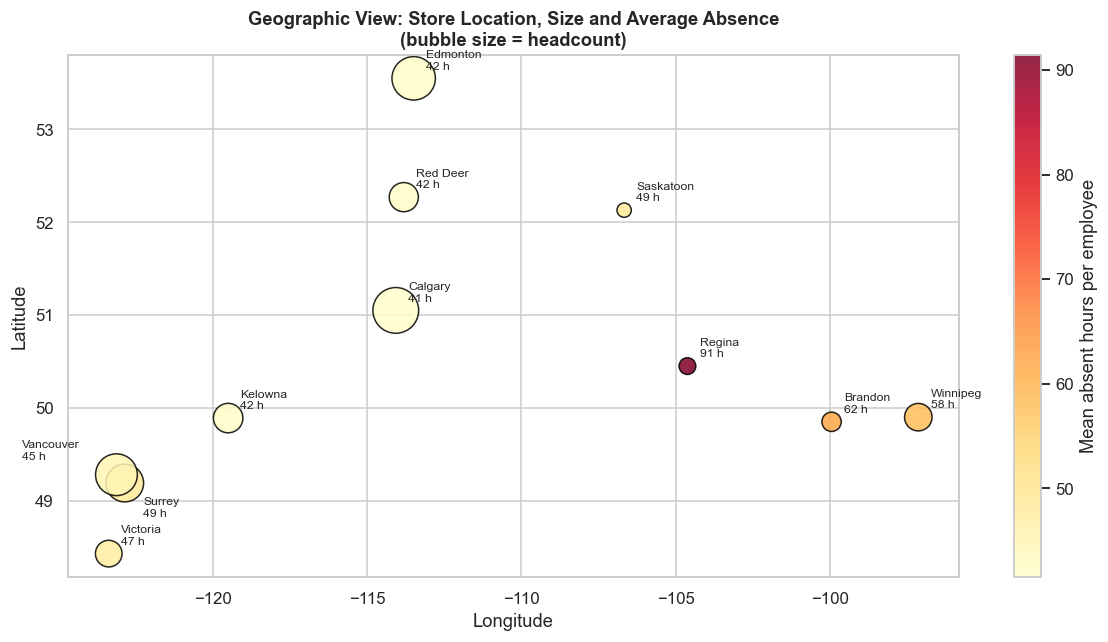

In [65]:
# Approximate city coordinates (latitude, longitude) used only for plotting; no basemap needed
coords = {"Calgary": (51.05, -114.07), "Edmonton": (53.55, -113.49), "Red Deer": (52.27, -113.81),
          "Vancouver": (49.28, -123.12), "Surrey": (49.19, -122.85), "Victoria": (48.43, -123.37),
          "Kelowna": (49.89, -119.50), "Winnipeg": (49.90, -97.14), "Brandon": (49.85, -99.95),
          "Regina": (50.45, -104.62), "Saskatoon": (52.13, -106.67)}
geo = a.groupby("City", observed=True).agg(Employees=("RecordID", "size"), Mean_abs=("AbsentHours", "mean")).reset_index()
geo["lat"] = geo.City.map(lambda c: coords[str(c)][0]); geo["lon"] = geo.City.map(lambda c: coords[str(c)][1])

fig, ax = plt.subplots(figsize=(11, 6))
pts = ax.scatter(geo.lon, geo.lat, s=geo.Employees * 4, c=geo.Mean_abs, cmap="YlOrRd", edgecolor="black", alpha=0.85)
offsets = {"Surrey": (12, -22), "Vancouver": (-62, 10)}      # avoid overlapping labels
for _, r in geo.iterrows():
    ax.annotate(f"{r.City}\n{r.Mean_abs:.0f} h", (r.lon, r.lat), xytext=offsets.get(str(r.City), (8, 6)),
                textcoords="offset points", fontsize=8)
plt.colorbar(pts, label="Mean absent hours per employee")
ax.set_title("Geographic View: Store Location, Size and Average Absence\n(bubble size = headcount)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
save(fig, "19_geographic_absence_map"); plt.show()

**Interpretation: geography.**
Absence rises **moving east from the Alberta and BC corridor into Saskatchewan and Manitoba**: the darkest bubbles are Regina, Brandon and Winnipeg, while Calgary, Edmonton and Red Deer are the lightest.
The Prairie-Central stores are also the smallest, which suggests thinner coverage and less management support, so absence in these stores is harder to absorb.

# PHASE 6: Risk Identification (Business Question 4)
We combine the earlier results to locate **absence clusters**, **tenure extremes**, **possible understaffing**, and a **store-level risk scorecard**.

### 6.1 Outliers, anomalies and data-quality concerns

In [66]:
anomaly = pd.DataFrame([
    ["Extreme absence (above IQR fence)", int(a.HighAbsence.sum()), "Likely long-term leave; concentrated in Sales and Customer Service roles"],
    ["Highest single absence", f"{a.AbsentHours.max():.0f} h ({a.AbsenceRate.max()*100:.0f}% of scheduled hours)", "Verify with HR whether this is leave, a data entry error or both"],
    ["Missing absence data", int(df.AbsentHours.isna().sum()), "Excluded from absence analysis"],
    ["Duplicate EmployeeIDs (different people)", 4, "HRIS key integrity problem"],
    ["Department label conflicts with job title", 2, "Corrected using job title; confirm with client"],
    ["Managers / assistant managers aged under 25", int(df.ImplausibleSeniority.sum()), "Possible job-title coding issue"],
    ["'Store Manager' titles vs number of stores", f"{int((df.JobTitle=='Store Manager').sum())} titles vs {df.StoreID.nunique()} stores", "Title probably means department manager; definition needed"],
    ["Placeholder hire dates (30-31 Dec 2025)", int(df.HireDatePlaceholder.sum()), "Zero tenure but full-year hours and absence; tenure results re-tested without them"],
    ["Missing Gender", int((df.Gender == 'Not recorded').sum()), "Labelled 'Not recorded'"],
], columns=["Item", "Count / value", "Comment"])
anomaly

# Where do the extreme-absence employees sit?
print(a[a.HighAbsence].groupby("Department", observed=True).size().sort_values(ascending=False).to_frame("Extreme cases"))

                  Extreme cases
Department                     
Sales                        31
Customer Service             15
Human Resources               2
Inventory                     1
Management                    1


**Interpretation: anomaly register.**
This table pulls together everything unusual in one place. The key operational point is that **46 of the 50 extreme-absence employees (92%) are in Sales or Customer Service**, so the extreme cases are not scattered across the company.
The data-quality items (duplicate IDs, placeholder hire dates, label conflicts, the "Store Manager" definition) should go to the client as a short data-fix list.

### 6.2 High-absence clusters (store x department)

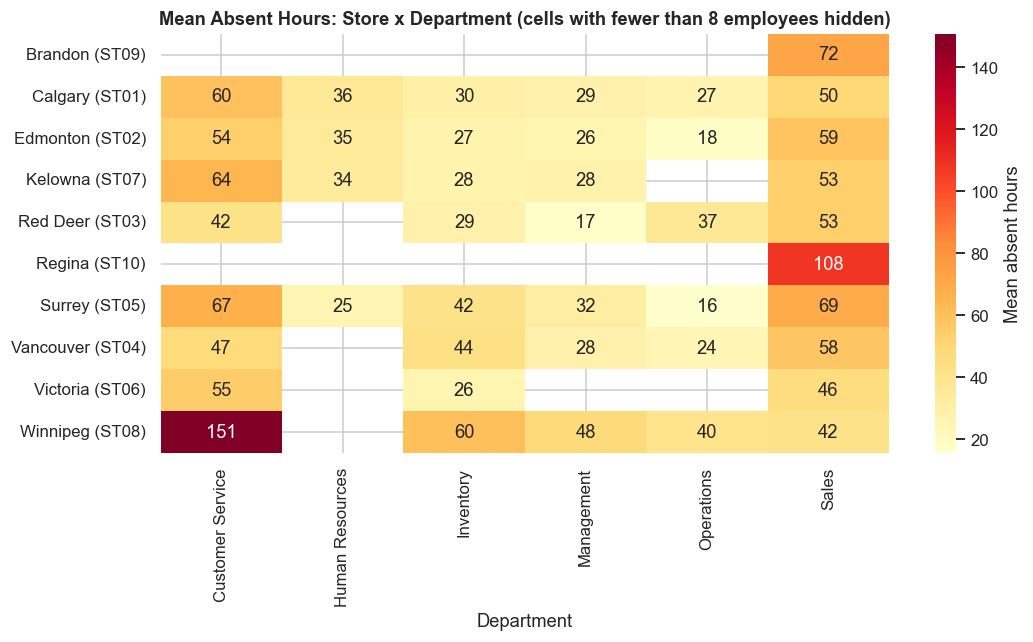

Clusters with mean absence at least 1.5x company mean (70 h), n >= 8:


,Store,Department,n,mean_abs,pct_extreme
59,Winnipeg (ST08),Customer Service,10,150.8,20.0
34,Regina (ST10),Sales,15,108.0,26.7
5,Brandon (ST09),Sales,24,71.7,12.5


In [67]:
MIN_N = 8   # hide cells with fewer employees; averages from tiny groups are unreliable
cell = a.groupby(["Store", "Department"], observed=True).agg(
    n=("RecordID", "size"), mean_abs=("AbsentHours", "mean"), pct_extreme=("HighAbsence", "mean")).reset_index()
cell["pct_extreme"] *= 100
shown = cell[cell.n >= MIN_N]

heat = shown.pivot(index="Store", columns="Department", values="mean_abs")
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "Mean absent hours"}, ax=ax)
ax.set_title(f"Mean Absent Hours: Store x Department (cells with fewer than {MIN_N} employees hidden)")
ax.set_ylabel("")
save(fig, "20_absence_cluster_heatmap"); plt.show()

hot = shown[shown.mean_abs >= a.AbsentHours.mean() * 1.5].sort_values("mean_abs", ascending=False)
print(f"Clusters with mean absence at least 1.5x company mean ({a.AbsentHours.mean()*1.5:.0f} h), n >= {MIN_N}:")
hot.round(1)

**Interpretation: high-absence clusters.**
Absence is **not evenly high across the company; it is concentrated in a few specific teams**. Three store-department teams run at 1.5x the company mean or more:
**Winnipeg Customer Service (151 h, n = 10, 20% extreme cases)**, **Regina Sales (108 h, n = 15, 27% extreme)** and **Brandon Sales (72 h, n = 24)**. The heatmap also shows Customer Service and Sales as warm colours across most stores,
while Operations, Management and Inventory are cool almost everywhere. Teams below 8 people are hidden because their averages are not reliable.

### 6.3 Teams with unusually low or high tenure

In [68]:
ten = df.groupby(["Store", "Department"], observed=True).agg(
    n=("RecordID", "size"), mean_tenure=("LengthOfServiceYears", "mean"),
    pct_new=("LengthOfServiceYears", lambda s: (s < TURNOVER_YRS).mean() * 100)).reset_index()
ten = ten[ten.n >= MIN_N]
co_mean, co_new = df.LengthOfServiceYears.mean(), (df.LengthOfServiceYears < TURNOVER_YRS).mean() * 100

low = ten[(ten.pct_new >= 35) | (ten.mean_tenure <= 2.5)].sort_values("pct_new", ascending=False)
high = ten[ten.mean_tenure >= 7].sort_values("mean_tenure", ascending=False)
print(f"Company: mean tenure {co_mean:.1f} yrs, {co_new:.1f}% under 1 year")
print("\nTeams with unusually LOW tenure (>=35% under 1 yr, or mean <= 2.5 yrs):")
print(low.round(1).to_string(index=False))
print("\nTeams with unusually HIGH tenure (mean >= 7 yrs): knowledge concentration / retirement exposure")
print(high.round(1).to_string(index=False))

Company: mean tenure 4.5 yrs, 20.6% under 1 year

Teams with unusually LOW tenure (>=35% under 1 yr, or mean <= 2.5 yrs):
          Store       Department  n  mean_tenure  pct_new
 Brandon (ST09)            Sales 24          2.9     41.7
 Kelowna (ST07) Customer Service 11          3.4     36.4
Victoria (ST06)            Sales 25          2.9     36.0
Red Deer (ST03)            Sales 35          2.5     28.6

Teams with unusually HIGH tenure (mean >= 7 yrs): knowledge concentration / retirement exposure
           Store      Department  n  mean_tenure  pct_new
 Edmonton (ST02) Human Resources  9          8.4     11.1
  Kelowna (ST07)      Management 12          7.5      8.3
   Surrey (ST05)      Operations 16          7.5      6.2
  Kelowna (ST07) Human Resources  8          7.4     25.0
 Winnipeg (ST08)      Management  9          7.4      0.0
 Red Deer (ST03)       Inventory 15          7.3      0.0
 Winnipeg (ST08)       Inventory 13          7.2      0.0
Vancouver (ST04)      Manag

**Interpretation: teams with unusually low or high tenure.**
**Low-tenure teams:** Brandon Sales (42% under one year), Kelowna Customer Service (36%), Victoria Sales (36%) and Red Deer Sales (mean tenure only 2.5 years) are churning or expanding quickly, which strains training and quality.
**High-tenure teams:** Edmonton HR (8.4 years), Kelowna Management (7.5), Surrey Operations (7.5) and several Inventory and Management teams are very stable; that is a strength but also a **knowledge-concentration and retirement-planning risk**.

### 6.4 Possible understaffing (observed vs expected department headcount)

In [69]:
# Expected headcount = store size x company-wide department share
dept_share = df.Department.value_counts(normalize=True)
obs = pd.crosstab(df.Store, df.Department)
exp = pd.DataFrame({d: obs.sum(axis=1) * dept_share[d] for d in obs.columns})
ratio = (obs / exp)

flags = []
for s in obs.index:
    for d in obs.columns:
        o, e = obs.loc[s, d], exp.loc[s, d]
        if o == 0 and e >= 1.5:
            flags.append([s, d, o, round(e, 1), 0.0, "No staff in this department"])
        elif e >= 2 and o / e <= 0.5:
            flags.append([s, d, o, round(e, 1), round(o / e, 2), "Thin: at most half of expected"])
        elif e >= 5 and o / e >= 1.5:
            flags.append([s, d, o, round(e, 1), round(o / e, 2), "Heavy: 1.5x expected or more"])
under = pd.DataFrame(flags, columns=["Store", "Department", "Observed", "Expected", "Ratio", "Flag"])
under.sort_values(["Flag", "Ratio"])

,Store,Department,Observed,Expected,Ratio,Flag
2,Kelowna (ST07),Human Resources,8,5.3,1.52,Heavy: 1.5x expected or more
1,Brandon (ST09),Sales,24,14.8,1.62,Heavy: 1.5x expected or more
3,Regina (ST10),Human Resources,0,1.7,0.00,No staff in this department
0,Brandon (ST09),Customer Service,1,6.4,0.16,Thin: at most half of expected
4,Saskatoon (ST11),Customer Service,1,3.5,0.29,Thin: at most half of expected
5,Victoria (ST06),Operations,4,8.8,0.45,Thin: at most half of expected


**Interpretation: possible understaffing.**
Using the company-wide department mix as a benchmark, the clearest gaps are **Brandon Customer Service (1 person against about 6 expected)**, **Saskatoon Customer Service (1 against about 3.5)**, **Victoria Operations (4 against about 9)** and
**Regina HR (none)**. At the other end, Brandon Sales (24 against about 15) is heavily weighted to Sales. The benchmark is an assumption: a small store might legitimately combine roles, so these are **questions to put to store managers**, not conclusions.

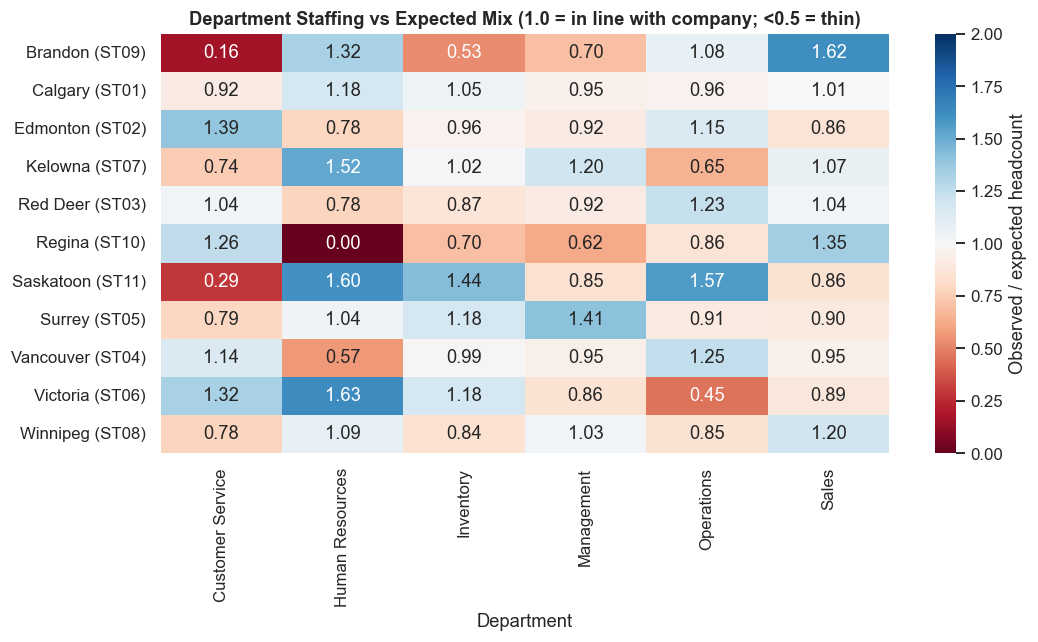

In [70]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(ratio, annot=True, fmt=".2f", cmap="RdBu", center=1, vmin=0, vmax=2,
            cbar_kws={"label": "Observed / expected headcount"}, ax=ax)
ax.set_title("Department Staffing vs Expected Mix (1.0 = in line with company; <0.5 = thin)")
ax.set_ylabel("")
save(fig, "21_staffing_ratio_heatmap"); plt.show()

### 6.5 Store risk scorecard

In [71]:
sc = pd.DataFrame({
    "Employees": df.groupby("Store", observed=True).size(),
    "AbsenceGap_h": adj["Gap_hours"],
    "PctExtremeAbsence": a.groupby("Store", observed=True).HighAbsence.mean() * 100,
    "Pct55plus": store_age["Pct_55plus"],
    "PctUnder1yr": store_age["Pct_under_1yr"],
    "StaffPerSupervisor": struct["Staff per supervisor"],
})
thin_counts = under[under.Flag.isin(["No staff in this department", "Thin: at most half of expected"])].groupby("Store").size()
sc["ThinOrMissingDepts"] = thin_counts.reindex(sc.index).fillna(0).astype(int)

risk_cols = ["AbsenceGap_h", "PctExtremeAbsence", "Pct55plus", "PctUnder1yr", "StaffPerSupervisor", "ThinOrMissingDepts"]
sc["RiskScore"] = sc[risk_cols].rank(pct=True).mean(axis=1).mul(100).round(0)       # 0-100, higher = riskier
sc["SmallStore(n<50)"] = np.where(sc.Employees < 50, "Yes", "")
sc = sc.sort_values("RiskScore", ascending=False).round(1)
sc

,Employees,AbsenceGap_h,PctExtremeAbsence,Pct55plus,PctUnder1yr,StaffPerSupervisor,ThinOrMissingDepts,RiskScore,SmallStore(n<50)
Store,,,,,,,,,
Saskatoon (ST11),22,6.5,4.5,13.6,18.2,7.3,1,77.0,Yes
Brandon (ST09),40,13.3,7.5,7.5,37.5,2.5,1,69.0,Yes
Regina (ST10),30,41.0,20.0,0.0,26.7,2.1,1,66.0,Yes
Victoria (ST06),76,-0.8,2.6,7.9,26.3,4.8,1,64.0,
Kelowna (ST07),93,-4.6,4.3,10.8,20.4,3.9,0,59.0,
Surrey (ST05),152,3.9,5.3,10.5,17.1,3.8,0,57.0,
Calgary (ST01),225,-5.1,4.0,8.0,21.3,3.8,0,48.0,
Vancouver (ST04),187,-1.6,2.1,9.6,19.3,3.7,0,44.0,
Winnipeg (ST08),81,10.7,6.2,1.2,16.0,3.0,0,42.0,


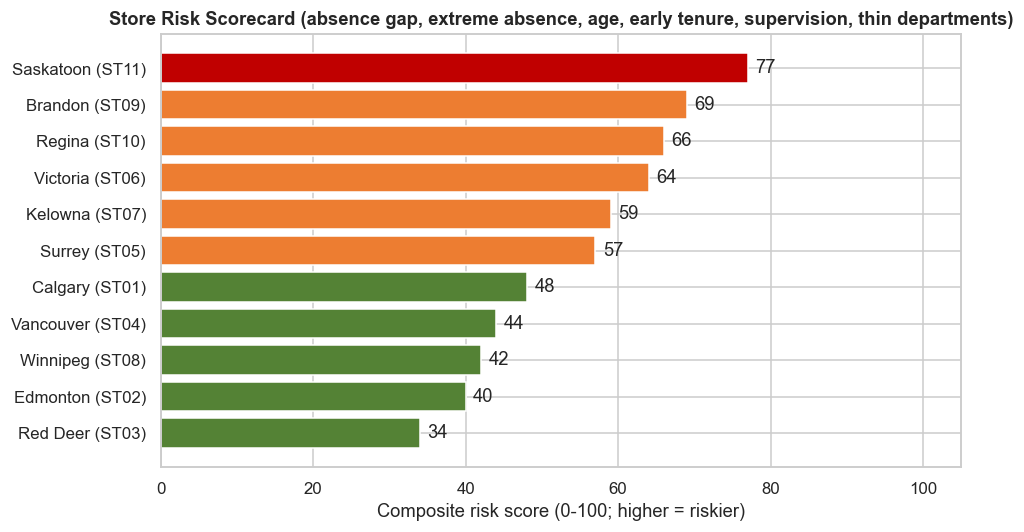

In [72]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#C00000" if v >= 70 else "#ED7D31" if v >= 50 else "#548235" for v in sc.RiskScore]
ax.barh(sc.index[::-1], sc.RiskScore[::-1], color=colors[::-1])
for i, v in enumerate(sc.RiskScore[::-1]):
    ax.text(v + 1, i, f"{v:.0f}", va="center")
ax.set_xlim(0, 105); ax.set_xlabel("Composite risk score (0-100; higher = riskier)")
ax.set_title("Store Risk Scorecard (absence gap, extreme absence, age, early tenure, supervision, thin departments)")
save(fig, "22_store_risk_scorecard"); plt.show()

**Interpretation: store risk scorecard.**
The score combines six signals into a 0 to 100 index (higher is riskier). **Saskatoon (77), Brandon (69), Regina (66) and Victoria (64)** rank highest, while the large Alberta stores (Edmonton 40, Red Deer 34) rank lowest. Three cautions:
the weights are equal, the score is rank-based, and the top three stores are small (22 to 40 employees) so their numbers move easily. **Regina has the single worst absence problem (+41 h)** but ranks third because it has no retirement exposure and dense supervision.
Use the scorecard to decide where to look first, not as a final verdict.

# PHASE 7: Strategic Opportunities (Business Question 5)
We size three improvement opportunities so recommendations can be prioritised by impact.

In [73]:
# Opportunity sizing (hours that could be recovered under simple "bring them to normal" scenarios)
# A) Stores above the department-mix expectation come back to expectation
A = adj.loc[adj.Gap_hours > 0, "Excess_hours_total"].sum()

# B) New hires (<1 yr) in Sales and Customer Service match the absence of their established colleagues
B = 0
for d in ["Sales", "Customer Service"]:
    x = a[a.Department == d]
    new, est = x[x.LengthOfServiceYears < 1], x[x.LengthOfServiceYears >= 1]
    B += max(new.AbsentHours.mean() - est.AbsentHours.mean(), 0) * len(new)

# C) Extreme absences: hours above the fence (mostly long-term leave; managed through return-to-work, not discipline)
C = (a.loc[a.HighAbsence, "AbsentHours"] - FENCE).sum()

opp = pd.DataFrame({
    "Opportunity": ["A. Stores above expected absence return to expected",
                    "B. New Sales/Customer Service hires match established staff",
                    "C. Extreme absences: return-to-work management (hours above fence)"],
    "Hours": [A, B, C]})
opp["FTE equivalent"] = (opp.Hours / 2080).round(1)
opp["% of all absent hours"] = (opp.Hours / a.AbsentHours.sum() * 100).round(1)
opp["Hours"] = opp.Hours.round(0)
opp

,Opportunity,Hours,FTE equivalent,% of all absent hours
0,A. Stores above expected absence return to exp...,3372.0,1.6,6.0
1,B. New Sales/Customer Service hires match esta...,3643.0,1.8,6.5
2,C. Extreme absences: return-to-work management...,4860.0,2.3,8.7


**Interpretation: size of the opportunity.**
Each scenario is worth roughly **6% to 9% of all absent hours (about 1.6 to 2.3 full-time positions)**: stores above expectation returning to normal (about 3,400 h), new Sales and Customer Service hires matching established staff (about 3,600 h), and
better management of the extreme cases (about 4,900 h). Company-wide absence is about 27 FTE, so no single action is transformational. The value lies in **targeting the right places** (a few stores, two departments, the first year of employment)
and in reducing the disruption and cover cost these absences cause, rather than in a large across-the-board cut.

**How to read this table.** The scenarios overlap (the same person can appear in more than one), so the rows should **not be added together**. They show where the biggest lever sits.

### Recommended actions

| # | Action | Owner | Evidence | KPI to track |
|---|---|---|---|---|
| 1 | **Regina turnaround plan**: management review, absence-reason analysis, and local support (also fill the missing HR presence, for example a shared regional HR partner) | Operations leadership + HR | About 91 h per employee, +41 h above expectation, 20% extreme cases, no HR staff | Regina mean absent hours; target within 15% of company mean in 12 months |
| 2 | **Strengthen onboarding and first-year support** in Sales and Customer Service (buddy system, 30/60/90-day check-ins, scheduling that fits young workers) | HR + store managers | Genuine new hires average about 78 h versus 49 h in Sales; under-25s are the highest-absence age band | Absence and 12-month retention of new hires |
| 3 | **Targeted attendance programme for Customer Service and Sales floors** (shift flexibility, workload review, wellness support) | Store managers | These two departments are 53% of staff and about 67% of absent hours | Department mean absent hours |
| 4 | **Return-to-work and long-term leave management** for the roughly 50 extreme cases | HR | They produce about a fifth of all absent hours despite being 4% of staff | Number of cases above 142 h; average days to return |
| 5 | **Rebalance staffing in small Prairie stores** (Brandon and Saskatoon have only one Customer Service employee each; Saskatoon has one supervisor per 7 staff) | Operations + store managers | Thin or missing departments and high supervisor spans | Staff-per-supervisor; coverage by department |
| 6 | **Succession plan for retirement-exposed groups**: HR Business Partners (25% aged 55+), HR (21%), Operations (15%), and 5 managers aged 55+ | HR | 99 employees aged 55+, 40 aged 60+ | Named successors for critical roles |
| 7 | **Share best practice** from Calgary, Edmonton, Red Deer and Kelowna (absence below expectation) | Operations | About 5 h per employee below expectation | Cross-store practice reviews |
| 8 | **Fix the data**: unique employee IDs, consistent department labels, define "Store Manager", record absence reasons | HR / HRIS team | Duplicate IDs, label conflicts, 2 missing absence records | Data-quality checks passing |

# PHASE 8: Summary Dashboard and Exports

In [74]:
kpi = pd.Series({
    "Employees": len(df),
    "Stores / Provinces": f"{df.StoreID.nunique()} / {df.Province.nunique()}",
    "Median age": df.AgeYears.median(),
    "Median tenure (yrs)": round(df.LengthOfServiceYears.median(), 1),
    "% aged 55+ (retirement watch)": round((df.AgeYears >= RETIRE_NEAR).mean() * 100, 1),
    "% under 1 yr service (turnover watch)": round((df.LengthOfServiceYears < TURNOVER_YRS).mean() * 100, 1),
    "Mean absent hours": round(a.AbsentHours.mean(), 1),
    "Median absent hours": a.AbsentHours.median(),
    "Company absence rate %": round(a.AbsentHours.sum() / a.ScheduledHours2025.sum() * 100, 2),
    "Highest-absence store": absence_table("Store").index[0],
    "Highest-absence department": absence_table("Department").index[0],
    "Highest-risk store (scorecard)": sc.index[0],
}).to_frame("Value")
kpi

,Value
Employees,1200
Stores / Provinces,11 / 4
Median age,38.0
Median tenure (yrs),3.1
% aged 55+ (retirement watch),8.2
% under 1 yr service (turnover watch),20.6
Mean absent hours,46.7
Median absent hours,32.0
Company absence rate %,2.52
Highest-absence store,Regina (ST10)


**Interpretation: headline numbers.**
This one-table summary is the starting point for the executive summary: a 1,200-person workforce with a median age of 38 and three years of service, 8% at retirement watch, a 2.5% absence rate concentrated in Customer Service and Sales,
Regina as the highest-absence store, and Saskatoon as the highest composite risk (a small store, so treat it with care).

In [75]:
# Save the final dataset and a workbook of the key tables (useful as an appendix to the report)
df.to_csv(OUT_DIR / "Keren_Oyem_Final_Analysis_Dataset.csv", index=False)

with pd.ExcelWriter(OUT_DIR / "Keren_Oyem_Analysis_Tables.xlsx") as xw:
    kpi.to_excel(xw, sheet_name="KPI summary")
    issues_log.to_excel(xw, sheet_name="Data issues log", index=False)
    freq("Department").to_excel(xw, sheet_name="Headcount_Dept")
    freq("Store").to_excel(xw, sheet_name="Headcount_Store")
    dept_age.to_excel(xw, sheet_name="Age_Tenure_Dept")
    store_age.to_excel(xw, sheet_name="Age_Tenure_Store")
    absence_table("Department").to_excel(xw, sheet_name="Absence_Dept")
    absence_table("JobTitle").to_excel(xw, sheet_name="Absence_JobTitle")
    absence_table("Store").to_excel(xw, sheet_name="Absence_Store")
    adj.to_excel(xw, sheet_name="Store_Adjusted_Gap")
    tests.to_excel(xw, sheet_name="Significance_tests", index=False)
    under.to_excel(xw, sheet_name="Staffing_flags", index=False)
    sc.to_excel(xw, sheet_name="Store_risk_scorecard")
    opp.to_excel(xw, sheet_name="Opportunity_sizing", index=False)
print("Saved Keren_Oyem_Final_Analysis_Dataset.csv and Keren_Oyem_Analysis_Tables.xlsx in", OUT_DIR.resolve())
print("Charts saved in", CHART_DIR.resolve())

Saved Keren_Oyem_Final_Analysis_Dataset.csv and Keren_Oyem_Analysis_Tables.xlsx in C:\Users\HP\Desktop\Absenteeism Project
Charts saved in C:\Users\HP\Desktop\Absenteeism Project\charts
